# Competing Causal Abstractions: Final Confirmation

This experiment asks which high-level algorithm best predicts both a model's clean answers and its response to frozen activation interventions.

[实验设置与运行说明](../../../docs/experiment_notes/08_appendix_error_structure/7efee40b77b9dfdb.md)


In [1]:
# Run once. Every later code cell reports both cell and inner-loop progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 17 tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 17 tracked cells.


## 1. Setup


In [2]:
%%cell_progress 1/17 Mount Drive and locate VisualTorque
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Locating VisualTorque project')
from pathlib import Path
PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
PROJECT_ROOT = next(
    (
        path for path in PROJECT_CANDIDATES
        if (path / 'toolkit' / 'pyproject.toml').is_file()
    ),
    None,
)
assert PROJECT_ROOT is not None, (
    'Could not find VisualTorque/toolkit/pyproject.toml on Drive.'
)
TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
print('Project:', PROJECT_ROOT)


Mount Drive and locate VisualTorque:   0%|          | 0/17 [00:00<?, ?cell/s]

Mounted at /content/drive
Project: /content/drive/MyDrive/VisualTorque


In [3]:
%%cell_progress 2/17 Install and verify the multimodal environment
import importlib
import os

os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')
import subprocess
import sys

cell_stage('Removing unused TorchAudio')
subprocess.run(
    [sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchaudio'],
    check=False,
)
cell_stage('Installing pinned inference and analysis dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    'transformers==5.14.0', 'accelerate>=1.10', 'sentencepiece',
    'protobuf', 'huggingface_hub>=0.34', 'hf_xet>=1.1', 'tqdm>=4.66',
    'pandas>=2.2', 'matplotlib>=3.8', 'scikit-learn>=1.5',
])

cell_stage('Registering the live VisualTorque source tree')
SRC_ROOT = TOOLKIT_ROOT / 'src'
PACKAGE_ROOT = SRC_ROOT / 'visual_torque_toolkit'
assert (PACKAGE_ROOT / '__init__.py').is_file(), PACKAGE_ROOT
source_text = str(SRC_ROOT)
sys.path[:] = [entry for entry in sys.path if entry != source_text]
sys.path.insert(0, source_text)
for module_name in tuple(sys.modules):
    if (
        module_name == 'visual_torque_toolkit'
        or module_name.startswith('visual_torque_toolkit.')
    ):
        del sys.modules[module_name]
importlib.invalidate_caches()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
import visual_torque_toolkit
from IPython.display import display
from transformers import AutoModelForMultimodalLM, AutoProcessor
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter

required_features = (
    '_template', '_to_device', '_candidate_plan', '_append_text_prefix',
)
assert all(
    hasattr(HuggingFaceMultimodalAdapter, name)
    for name in required_features
)
toolkit_path = Path(visual_torque_toolkit.__file__).resolve()
assert PACKAGE_ROOT.resolve() in toolkit_path.parents, toolkit_path
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('torchvision:', torchvision.__version__)
print('Toolkit source:', toolkit_path)


Install and verify the multimodal environment:   6%|5         | 1/17 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
torchvision: 0.26.0+cu128
Toolkit source: /content/drive/MyDrive/VisualTorque/toolkit/src/visual_torque_toolkit/__init__.py


In [4]:
%%cell_progress 3/17 Verify A100 and Hugging Face access
cell_stage('Checking CUDA device')
assert torch.cuda.is_available(), 'Select an A100 GPU runtime.'
print(torch.cuda.get_device_name(0))
print('CUDA memory (GB):', round(
    torch.cuda.get_device_properties(0).total_memory / 2**30, 1
))

cell_stage('Authenticating with Hugging Face')
from google.colab import userdata
from huggingface_hub import login
try:
    token = userdata.get('HF_TOKEN')
    if token:
        login(token=token, add_to_git_credential=False)
        print('Hugging Face login complete.')
    else:
        print('HF_TOKEN is not set. Public checkpoints may still work.')
except Exception as exc:
    print('Hugging Face login skipped:', exc)


Verify A100 and Hugging Face access:  12%|#1        | 2/17 [00:00<?, ?cell/s]

NVIDIA RTX PRO 6000 Blackwell Server Edition
CUDA memory (GB): 95.0
Hugging Face login skipped: Secret HF_TOKEN does not exist.


In [5]:
%%cell_progress 4/17 Lock the competing-abstraction protocol
cell_stage('Freezing models, candidate algorithms, splits, sites, and gates')
import hashlib
import json
from datetime import datetime, timezone

# Run qwen9b first, then gemma12b and qwen27b in fresh runtimes.
MODEL_KEY = 'qwen9b'

MODEL_SPECS = {
    'qwen9b': {
        'model_id': 'Qwen/Qwen3.5-9B',
        'model_slug': 'Qwen__Qwen3.5-9B',
        'expected_layers': 32,
        'revision': None,
        'sites': (
            (16, 'pre_options_tokens', 'composition_preoptions'),
            (16, 'options_tokens', 'composition_options'),
            (27, 'final_prompt_token', 'answer'),
        ),
    },
    'gemma12b': {
        'model_id': 'google/gemma-4-12B-it',
        'model_slug': 'google__gemma-4-12B-it',
        'expected_layers': 48,
        'revision': None,
        'sites': (
            (25, 'pre_options_tokens', 'composition_preoptions'),
            (25, 'options_tokens', 'composition_options'),
            (41, 'final_prompt_token', 'answer'),
        ),
    },
    'qwen27b': {
        'model_id': 'Qwen/Qwen3.5-27B',
        'model_slug': 'Qwen__Qwen3.5-27B__373612cb',
        'expected_layers': 64,
        'revision': '373612cb4f9288fcf550b526d86d85febedd9801',
        'sites': (
            (48, 'pre_options_tokens', 'composition_preoptions'),
            (48, 'options_tokens', 'composition_options'),
            (63, 'final_prompt_token', 'answer'),
        ),
    },
}
assert MODEL_KEY in MODEL_SPECS
SPEC = MODEL_SPECS[MODEL_KEY]
MODEL_ID = SPEC['model_id']
MODEL_SLUG = SPEC['model_slug']
EXPECTED_LAYER_COUNT = SPEC['expected_layers']
FROZEN_SITES = SPEC['sites']
CAPTURE_LAYERS = tuple(sorted({layer for layer, _, _ in FROZEN_SITES}))
PRIMARY_SITE_ROLE = 'composition_preoptions'

if SPEC['revision'] is None:
    revision_artifact = (
        PROJECT_ROOT / 'results' / MODEL_SLUG
        / 'activation_discovery_v1' / 'capture_config.json'
    )
    assert revision_artifact.is_file(), (
        'Missing the prior activation-discovery capture needed to pin this '
        f'model revision: {revision_artifact}'
    )
    revision_payload = json.loads(revision_artifact.read_text(encoding='utf-8'))
    MODEL_REVISION = str(revision_payload['identity']['resolved_revision'])
else:
    MODEL_REVISION = str(SPEC['revision'])

MODEL_DTYPE = 'bfloat16'
DEVICE_MAP = 'auto'
SEED = 20261027
CANDIDATE_STRATEGIES = (
    'exact_torque', 'weight_only', 'distance_only',
    'max_contribution', 'lexicographic',
)
DIAGNOSTIC_CELLS = (
    'weight_conflict', 'distance_conflict', 'max_vs_sum',
    'lexicographic_conflict', 'equal_torque_recomposition',
    'congruent_high',
)
TARGET_STRATEGY = {
    'weight_conflict': 'weight_only',
    'distance_conflict': 'distance_only',
    'max_vs_sum': 'max_contribution',
    'lexicographic_conflict': 'lexicographic',
}
FAMILIES_PER_CELL = 20
CALIBRATION_PER_CELL = 8
CONFIRMATION_PER_CELL = 12
EXPECTED_FAMILIES = len(DIAGNOSTIC_CELLS) * FAMILIES_PER_CELL
SCENE_ROLES = ('base', 'mirror_source', 'invariant_source')
INTERVENTIONS = ('self_base', 'mirror_source', 'invariant_source')
PROMPT_STYLES = ('semantic', 'nonce')
CAUSAL_PROMPT_STYLE = 'semantic'
PATCH_CONDITION_BATCH_SIZE = 1 if MODEL_KEY == 'qwen27b' else 2
BOOTSTRAP_REPLICATES = 10000
ALPHA = 0.05
EQUIVALENCE_FRACTION = 0.25
SMOKE_MAX_SELF_REPLAY_ERROR = 0.15
IMAGE_TOKEN_ID_OVERRIDE = None
REQUIRED_SCOPES = (
    'valid_tokens', 'pre_options_tokens', 'options_tokens',
    'final_prompt_token',
)

SHARED_ROOT = (
    PROJECT_ROOT / 'results'
    / 'competing_causal_abstraction_final_confirmatory_v1'
)
MANIFEST_PATH = SHARED_ROOT / 'strategy_family_manifest.jsonl'
MANIFEST_LOCK_PATH = SHARED_ROOT / 'manifest_lock.json'
PROTOCOL_LOCK_PATH = SHARED_ROOT / 'frozen_protocol.json'
SCENE_DIR = SHARED_ROOT / 'rendered_scenes'
OUTPUT_ROOT = SHARED_ROOT / 'models' / MODEL_SLUG
SHARD_DIR = OUTPUT_ROOT / 'family_shards'
ANALYSIS_DIR = OUTPUT_ROOT / 'analysis'
FIGURE_DIR = ANALYSIS_DIR / 'figures'
CROSS_MODEL_DIR = SHARED_ROOT / 'cross_model_analysis'
for path in (
    SHARED_ROOT, SCENE_DIR, OUTPUT_ROOT, SHARD_DIR, ANALYSIS_DIR,
    FIGURE_DIR, CROSS_MODEL_DIR,
):
    path.mkdir(parents=True, exist_ok=True)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return 'sha256:' + digest.hexdigest()

def write_json_atomic(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False) + '\n',
        encoding='utf-8',
    )
    temporary.replace(path)

protocol_identity = {
    'schema_version': 'competing-causal-abstraction-final-confirmatory-1.0',
    'analysis_status': 'calibration_then_locked_confirmation',
    'candidate_strategies': list(CANDIDATE_STRATEGIES),
    'strategy_definitions': {
        'exact_torque': 'sign(sum_left(w*d)-sum_right(w*d))',
        'weight_only': 'sign(sum_left(w)-sum_right(w))',
        'distance_only': 'sign(sum_left(d)-sum_right(d))',
        'max_contribution': 'sign(max_left(w*d)-max_right(w*d))',
        'lexicographic': (
            'use weight difference when abs(delta_weight)>1; otherwise '
            'use summed-distance difference'
        ),
        'conditional_selector': (
            'select one frozen candidate per diagnostic cell on calibration '
            'families only; evaluate without refitting on confirmation families'
        ),
    },
    'diagnostic_cells': list(DIAGNOSTIC_CELLS),
    'families_per_cell': FAMILIES_PER_CELL,
    'calibration_per_cell': CALIBRATION_PER_CELL,
    'confirmation_per_cell': CONFIRMATION_PER_CELL,
    'scene_roles': list(SCENE_ROLES),
    'interventions': list(INTERVENTIONS),
    'prompt_styles': list(PROMPT_STYLES),
    'model_sites': {
        key: [list(site) for site in value['sites']]
        for key, value in MODEL_SPECS.items()
    },
    'primary_site_role': PRIMARY_SITE_ROLE,
    'primary_behavior_estimand': (
        'confirmation-family log probability assigned to each frozen '
        'strategy prediction; exact-minus-target heuristic is paired by family'
    ),
    'primary_causal_estimand': (
        'self-replay-centered mirror-source log-odds transport for exact '
        'torque minus the predeclared competing heuristic'
    ),
    'invariance_gate': (
        'upper bootstrap confidence limit of equal-net recomposition '
        'self-centered total-variation change below 0.25 times the median '
        'mirror-source total-variation change'
    ),
    'support_gate': (
        'a strategy label requires behavior and causal contrasts to agree '
        'on untouched confirmation families; otherwise dissociated or unresolved'
    ),
    'bootstrap_unit': 'strategy family',
    'bootstrap_replicates': BOOTSTRAP_REPLICATES,
    'multiplicity': (
        'BH across the four primary diagnostic-cell contrasts at the '
        'composition-preoptions site'
    ),
    'seed': SEED,
    'nonconditioning_rule': (
        'model correctness never selects families and never defines the '
        'primary estimand'
    ),
    'interpretation_limit': (
        'grouped residual-stream interchange compares candidate causal '
        'abstractions at previously frozen sites; it does not identify a '
        'unique circuit or prove human-like serial calculation'
    ),
}
if PROTOCOL_LOCK_PATH.is_file():
    previous = json.loads(PROTOCOL_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == protocol_identity, (
        'Protocol changed. Use a new versioned experiment directory.'
    )
else:
    write_json_atomic(PROTOCOL_LOCK_PATH, {
        'identity': protocol_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

print('Model run:', MODEL_KEY, MODEL_ID, '@', MODEL_REVISION)
print('Families:', EXPECTED_FAMILIES, '| calibration:',
      CALIBRATION_PER_CELL, 'per cell | confirmation:',
      CONFIRMATION_PER_CELL, 'per cell')
print('Frozen sites:', FROZEN_SITES)
print('Shared output:', SHARED_ROOT)


Lock the competing-abstraction protocol:  18%|#7        | 3/17 [00:00<?, ?cell/s]

Model run: qwen9b Qwen/Qwen3.5-9B @ c202236235762e1c871ad0ccb60c8ee5ba337b9a
Families: 120 | calibration: 8 per cell | confirmation: 12 per cell
Frozen sites: ((16, 'pre_options_tokens', 'composition_preoptions'), (16, 'options_tokens', 'composition_options'), (27, 'final_prompt_token', 'answer'))
Shared output: /content/drive/MyDrive/VisualTorque/results/competing_causal_abstraction_final_confirmatory_v1


In [6]:
%%cell_progress 5/17 Prepare Dataset v1 on local SSD
cell_stage('Checking local and Drive dataset caches')
from zipfile import ZipFile

REQUIRED_DATASET_FILES = {
    'dataset_config.json', 'scenes.jsonl', 'counterfactual_pairs.jsonl',
    'questions.jsonl', 'splits.json', 'statistics.json',
}
DATASET_DIR = Path('/content/visualtorque_dataset_v1')
DATASET_ARCHIVE = PROJECT_ROOT / 'data' / 'dataset_v1.zip'
LEGACY_DATASET_DIR = PROJECT_ROOT / 'data' / 'dataset_v1'

def dataset_complete(path):
    return path.is_dir() and all(
        (path / name).is_file() for name in REQUIRED_DATASET_FILES
    )

if not dataset_complete(DATASET_DIR):
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if DATASET_ARCHIVE.is_file():
        cell_stage('Extracting Dataset v1 archive')
        with ZipFile(DATASET_ARCHIVE, 'r') as bundle:
            members = [m for m in bundle.infolist() if not m.is_dir()]
            root = DATASET_DIR.resolve()
            for member in tqdm(members, desc='Extracting Dataset v1', unit='file'):
                target = (DATASET_DIR / member.filename).resolve()
                if root not in target.parents:
                    raise ValueError(f'Unsafe archive path: {member.filename}')
                bundle.extract(member, DATASET_DIR)
    elif dataset_complete(LEGACY_DATASET_DIR):
        DATASET_DIR = LEGACY_DATASET_DIR
    else:
        raise FileNotFoundError(
            'Run the Dataset v1 build/cache cell in the behavior notebook first.'
        )
assert dataset_complete(DATASET_DIR)
print('Dataset:', DATASET_DIR)


Prepare Dataset v1 on local SSD:  24%|##3       | 4/17 [00:00<?, ?cell/s]

Extracting Dataset v1:   0%|          | 0/2106 [00:00<?, ?file/s]

Dataset: /content/visualtorque_dataset_v1


## 2. New strategy-diagnostic confirmation support


In [7]:
%%cell_progress 6/17 Build the independent strategy-diagnostic manifest
cell_stage('Enumerating new single-stack and multi-stack geometries')
from collections import Counter, defaultdict
from itertools import combinations, product

from visual_torque_toolkit.render import render_scene
from visual_torque_toolkit.world import Scene, Side, Stack

def read_jsonl(path):
    with Path(path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

def write_jsonl_atomic(path, rows):
    temporary = Path(path).with_suffix(Path(path).suffix + '.tmp')
    with temporary.open('w', encoding='utf-8') as handle:
        for row in rows:
            handle.write(json.dumps(row, sort_keys=True) + '\n')
    temporary.replace(path)

def stable_key(value):
    return hashlib.sha256(f'{SEED}:{value}'.encode('utf-8')).hexdigest()

def sign(value):
    return int(value > 0) - int(value < 0)

def outcome(value):
    return 'left' if value > 0 else 'right' if value < 0 else 'balanced'

def canonical_signature(stacks):
    return tuple(sorted(
        (str(stack['side']), int(stack['distance']), int(stack['units']))
        for stack in stacks
    ))

def mirror_stacks(stacks):
    return [
        {
            'side': 'right' if stack['side'] == 'left' else 'left',
            'distance': int(stack['distance']),
            'units': int(stack['units']),
        }
        for stack in stacks
    ]

def scene_features(stacks):
    left = [stack for stack in stacks if stack['side'] == 'left']
    right = [stack for stack in stacks if stack['side'] == 'right']
    left_torque = sum(int(s['units']) * int(s['distance']) for s in left)
    right_torque = sum(int(s['units']) * int(s['distance']) for s in right)
    delta_torque = left_torque - right_torque
    delta_weight = sum(int(s['units']) for s in left) - sum(
        int(s['units']) for s in right
    )
    delta_distance = sum(int(s['distance']) for s in left) - sum(
        int(s['distance']) for s in right
    )
    max_left = max(int(s['units']) * int(s['distance']) for s in left)
    max_right = max(int(s['units']) * int(s['distance']) for s in right)
    delta_max = max_left - max_right
    lexical_score = (
        delta_weight if abs(delta_weight) > 1 else delta_distance
    )
    scores = {
        'exact_torque': int(delta_torque),
        'weight_only': int(delta_weight),
        'distance_only': int(delta_distance),
        'max_contribution': int(delta_max),
        'lexicographic': int(lexical_score),
    }
    predictions = {name: outcome(value) for name, value in scores.items()}
    return {
        'left_torque': int(left_torque),
        'right_torque': int(right_torque),
        'net_torque': int(delta_torque),
        'total_torque': int(left_torque + right_torque),
        'normalized_margin': float(
            abs(delta_torque) / max(1, left_torque + right_torque)
        ),
        'strategy_scores': scores,
        'strategy_predictions': predictions,
        'outcome': predictions['exact_torque'],
        'stack_count': len(stacks),
    }

def classify_diagnostic(features):
    prediction = features['strategy_predictions']
    exact = prediction['exact_torque']
    if exact == 'balanced':
        return None
    if (
        prediction['weight_only'] != exact
        and prediction['distance_only'] == exact
        and prediction['weight_only'] != 'balanced'
    ):
        return 'weight_conflict'
    if (
        prediction['distance_only'] != exact
        and prediction['weight_only'] == exact
        and prediction['distance_only'] != 'balanced'
    ):
        return 'distance_conflict'
    if (
        features['stack_count'] > 2
        and prediction['max_contribution'] != exact
        and prediction['max_contribution'] != 'balanced'
    ):
        return 'max_vs_sum'
    if (
        prediction['lexicographic'] != exact
        and prediction['lexicographic'] != 'balanced'
    ):
        return 'lexicographic_conflict'
    nonzero = [prediction[name] for name in CANDIDATE_STRATEGIES]
    if (
        len(set(nonzero)) == 1
        and exact != 'balanced'
        and features['normalized_margin'] >= 0.35
    ):
        return 'congruent_high'
    return None

dataset_rows = read_jsonl(DATASET_DIR / 'scenes.jsonl')
dataset_signatures = {
    canonical_signature(row['stacks']) for row in dataset_rows
}

pool_by_signature = {}
for lu, ld, ru, rd in product(range(1, 7), repeat=4):
    stacks = [
        {'side': 'left', 'distance': ld, 'units': lu},
        {'side': 'right', 'distance': rd, 'units': ru},
    ]
    signature = canonical_signature(stacks)
    if signature in dataset_signatures:
        continue
    features = scene_features(stacks)
    if features['outcome'] != 'balanced':
        pool_by_signature[signature] = {
            'stacks': stacks, 'signature': signature, **features,
        }

for left_distances in combinations(range(1, 7), 2):
    for right_distances in combinations(range(1, 7), 2):
        for units in product(range(1, 5), repeat=4):
            stacks = [
                {'side': 'left', 'distance': left_distances[0], 'units': units[0]},
                {'side': 'left', 'distance': left_distances[1], 'units': units[1]},
                {'side': 'right', 'distance': right_distances[0], 'units': units[2]},
                {'side': 'right', 'distance': right_distances[1], 'units': units[3]},
            ]
            signature = canonical_signature(stacks)
            if signature in dataset_signatures:
                continue
            features = scene_features(stacks)
            if features['outcome'] != 'balanced':
                pool_by_signature[signature] = {
                    'stacks': stacks, 'signature': signature, **features,
                }

pool = list(pool_by_signature.values())
by_net = defaultdict(list)
by_cell = defaultdict(list)
for record in pool:
    by_net[int(record['net_torque'])].append(record)
    diagnostic = classify_diagnostic(record)
    if diagnostic is not None:
        by_cell[diagnostic].append(record)
for records in by_net.values():
    records.sort(key=lambda row: stable_key(row['signature']))
for records in by_cell.values():
    records.sort(key=lambda row: stable_key(row['signature']))

def different_predictions(left, right):
    return [
        name for name in CANDIDATE_STRATEGIES
        if left['strategy_predictions'][name]
        != right['strategy_predictions'][name]
    ]

def invariant_candidates(base, used_signatures, require_two=False):
    candidates = []
    for donor in by_net[int(base['net_torque'])]:
        signature = donor['signature']
        mirror_signature = canonical_signature(mirror_stacks(donor['stacks']))
        if signature in used_signatures or mirror_signature in used_signatures:
            continue
        if signature == base['signature']:
            continue
        differences = different_predictions(base, donor)
        required = 2 if require_two else 1
        if len(differences) < required:
            continue
        geometry_distance = sum(
            abs(a[1] - b[1]) + abs(a[2] - b[2])
            for a, b in zip(base['signature'], donor['signature'])
        ) if len(base['signature']) == len(donor['signature']) else 99
        candidates.append((
            -len(differences), geometry_distance,
            stable_key((base['signature'], signature)), donor,
        ))
    candidates.sort(key=lambda value: value[:-1])
    return [value[-1] for value in candidates]

cell_stage('Selecting balanced, scene-disjoint diagnostic families')
selected = []
used_signatures = set()

def append_family(cell_name, base, donor, cell_index):
    mirror = {
        'stacks': mirror_stacks(base['stacks']),
    }
    mirror.update(scene_features(mirror['stacks']))
    mirror['signature'] = canonical_signature(mirror['stacks'])
    assert mirror['net_torque'] == -base['net_torque']
    assert donor['net_torque'] == base['net_torque']
    differences = different_predictions(base, donor)
    diagnostic_strategy = (
        TARGET_STRATEGY[cell_name]
        if cell_name in TARGET_STRATEGY
        else differences[0] if differences else 'weight_only'
    )
    family_id = 'abstraction_' + hashlib.sha256(
        repr((cell_name, base['signature'], donor['signature'])).encode('utf-8')
    ).hexdigest()[:18]
    split = (
        'calibration' if cell_index < CALIBRATION_PER_CELL
        else 'confirmation'
    )
    roles = {}
    for role, scene_record in (
        ('base', base), ('mirror_source', mirror),
        ('invariant_source', donor),
    ):
        scene_id = family_id + '__' + role
        roles[role] = {
            'scene_id': scene_id,
            'image_filename': scene_id + '.png',
            'stacks': scene_record['stacks'],
            'features': {
                key: value for key, value in scene_record.items()
                if key not in {'stacks', 'signature'}
            },
        }
    selected.append({
        'family_id': family_id,
        'diagnostic_cell': cell_name,
        'split': split,
        'diagnostic_strategy': diagnostic_strategy,
        'base_outcome': base['outcome'],
        'invariant_strategy_differences': differences,
        'roles': roles,
    })
    used_signatures.update({
        base['signature'], mirror['signature'], donor['signature'],
    })

for cell_name in (
    'weight_conflict', 'distance_conflict', 'max_vs_sum',
    'lexicographic_conflict', 'congruent_high',
):
    chosen = 0
    for candidate in by_cell[cell_name]:
        desired = 'left' if chosen % 2 == 0 else 'right'
        base = candidate
        if candidate['outcome'] != desired:
            mirrored_signature = canonical_signature(mirror_stacks(candidate['stacks']))
            base = pool_by_signature.get(mirrored_signature)
            if base is None:
                continue
        base_mirror = canonical_signature(mirror_stacks(base['stacks']))
        if base['signature'] in used_signatures or base_mirror in used_signatures:
            continue
        donors = invariant_candidates(base, used_signatures | {
            base['signature'], base_mirror,
        })
        if not donors:
            continue
        append_family(cell_name, base, donors[0], chosen)
        chosen += 1
        if chosen == FAMILIES_PER_CELL:
            break
    assert chosen == FAMILIES_PER_CELL, (cell_name, chosen)

cell_stage('Selecting equal-torque recomposition families')
chosen = 0
recomposition_bases = sorted(
    [row for row in pool if row['stack_count'] > 2],
    key=lambda row: stable_key(('recomposition', row['signature'])),
)
for candidate in recomposition_bases:
    desired = 'left' if chosen % 2 == 0 else 'right'
    base = candidate
    if candidate['outcome'] != desired:
        mirrored_signature = canonical_signature(mirror_stacks(candidate['stacks']))
        base = pool_by_signature.get(mirrored_signature)
        if base is None:
            continue
    base_mirror = canonical_signature(mirror_stacks(base['stacks']))
    if base['signature'] in used_signatures or base_mirror in used_signatures:
        continue
    donors = invariant_candidates(
        base, used_signatures | {base['signature'], base_mirror},
        require_two=True,
    )
    if not donors:
        continue
    append_family('equal_torque_recomposition', base, donors[0], chosen)
    chosen += 1
    if chosen == FAMILIES_PER_CELL:
        break
assert chosen == FAMILIES_PER_CELL, ('equal_torque_recomposition', chosen)

selected.sort(key=lambda row: row['family_id'])
assert len(selected) == EXPECTED_FAMILIES
assert len(used_signatures) == EXPECTED_FAMILIES * 3
counts = Counter((row['diagnostic_cell'], row['split']) for row in selected)
for cell_name in DIAGNOSTIC_CELLS:
    assert counts[(cell_name, 'calibration')] == CALIBRATION_PER_CELL
    assert counts[(cell_name, 'confirmation')] == CONFIRMATION_PER_CELL
    outcomes = Counter(
        row['base_outcome'] for row in selected
        if row['diagnostic_cell'] == cell_name
    )
    assert outcomes == {'left': 10, 'right': 10}, (cell_name, outcomes)

manifest_identity = {
    'schema_version': 'strategy-diagnostic-family-manifest-1.0',
    'dataset_scenes_sha256': sha256_file(DATASET_DIR / 'scenes.jsonl'),
    'dataset_geometries_excluded': True,
    'model_outputs_consulted': False,
    'selection_seed': SEED,
    'pool_size': len(pool),
    'families': EXPECTED_FAMILIES,
    'unique_geometries': len(used_signatures),
    'cell_counts': {
        f'{cell}:{split}': int(count)
        for (cell, split), count in sorted(counts.items())
    },
    'family_ids': [row['family_id'] for row in selected],
}
if MANIFEST_LOCK_PATH.is_file():
    previous = json.loads(MANIFEST_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == manifest_identity
    assert read_jsonl(MANIFEST_PATH) == selected
else:
    write_jsonl_atomic(MANIFEST_PATH, selected)
    write_json_atomic(MANIFEST_LOCK_PATH, {
        'identity': manifest_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

strategy_manifest = read_jsonl(MANIFEST_PATH)
cell_stage('Rendering or verifying 360 persistent diagnostic scenes')
for row in tqdm(strategy_manifest, desc='Rendering strategy scenes', unit='scene-family'):
    for role in SCENE_ROLES:
        role_record = row['roles'][role]
        image_path = SCENE_DIR / role_record['image_filename']
        if image_path.is_file():
            continue
        stacks = tuple(
            Stack(
                stack_id=f'{role}_{index}',
                side=Side(str(stack['side'])),
                distance=int(stack['distance']),
                units=int(stack['units']),
            )
            for index, stack in enumerate(role_record['stacks'])
        )
        render_scene(Scene(role_record['scene_id'], stacks), image_path)
for row in strategy_manifest:
    for role in SCENE_ROLES:
        assert (SCENE_DIR / row['roles'][role]['image_filename']).is_file()

manifest_frame = pd.DataFrame([{
    'family_id': row['family_id'],
    'diagnostic_cell': row['diagnostic_cell'],
    'split': row['split'],
    'diagnostic_strategy': row['diagnostic_strategy'],
    'base_outcome': row['base_outcome'],
    'invariant_strategy_differences': ','.join(
        row['invariant_strategy_differences']
    ),
} for row in strategy_manifest])
manifest_frame.to_csv(SHARED_ROOT / 'strategy_family_manifest.csv', index=False)
identifiability_rows = []
for cell_name in DIAGNOSTIC_CELLS:
    cell_rows = [
        row for row in strategy_manifest
        if row['diagnostic_cell'] == cell_name
    ]
    for left_index, left_strategy in enumerate(CANDIDATE_STRATEGIES):
        for right_strategy in CANDIDATE_STRATEGIES[left_index + 1:]:
            disagreements = [
                row['roles']['base']['features']['strategy_predictions'][left_strategy]
                != row['roles']['base']['features']['strategy_predictions'][right_strategy]
                for row in cell_rows
            ]
            identifiability_rows.append({
                'diagnostic_cell': cell_name,
                'left_strategy': left_strategy,
                'right_strategy': right_strategy,
                'base_prediction_disagreement_rate': float(np.mean(disagreements)),
            })
identifiability_frame = pd.DataFrame(identifiability_rows)
identifiability_frame.to_csv(
    SHARED_ROOT / 'strategy_identifiability.csv', index=False
)
display(manifest_frame.groupby([
    'diagnostic_cell', 'split', 'base_outcome'
]).size().rename('n').reset_index())
print('Pool:', len(pool), '| selected families:', len(strategy_manifest))
print('New rendered geometries:', len(used_signatures))


Build the independent strategy-diagnostic manifest:  29%|##9       | 5/17 [00:00<?, ?cell/s]

Rendering strategy scenes:   0%|          | 0/120 [00:00<?, ?scene-family/s]

,diagnostic_cell,split,base_outcome,n
0,congruent_high,calibration,left,4
1,congruent_high,calibration,right,4
2,congruent_high,confirmation,left,6
3,congruent_high,confirmation,right,6
4,distance_conflict,calibration,left,4
5,distance_conflict,calibration,right,4
6,distance_conflict,confirmation,left,6
7,distance_conflict,confirmation,right,6
8,equal_torque_recomposition,calibration,left,4
9,equal_torque_recomposition,calibration,right,4


Pool: 54818 | selected families: 120
New rendered geometries: 360


In [8]:
%%cell_progress 7/17 Load the pinned model and resolve frozen decoder layers
cell_stage(f'Loading pinned {MODEL_KEY} weights')
import gc
if 'adapter' in globals():
    del adapter
    gc.collect()
    torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

adapter = HuggingFaceMultimodalAdapter(
    MODEL_ID, revision=MODEL_REVISION,
    dtype=MODEL_DTYPE, device_map=DEVICE_MAP,
)
display(adapter.metadata)
resolved_revision = str(adapter.metadata.get('resolved_revision'))
assert resolved_revision == MODEL_REVISION, (
    resolved_revision, MODEL_REVISION
)

def resolve_module_path(root, path):
    value = root
    for component in path.split('.'):
        value = getattr(value, component)
    return value

def discover_decoder_layers(model):
    candidates = (
        'model.language_model.layers', 'model.text_model.layers',
        'language_model.model.layers', 'model.model.layers', 'model.layers',
    )
    for path in candidates:
        try:
            layers = resolve_module_path(model, path)
        except AttributeError:
            continue
        if isinstance(layers, torch.nn.ModuleList) and len(layers) >= 8:
            return path, layers
    raise RuntimeError('Could not locate decoder layers.')

LAYER_PATH, DECODER_LAYERS = discover_decoder_layers(adapter.model)
assert len(DECODER_LAYERS) == EXPECTED_LAYER_COUNT, (
    LAYER_PATH, len(DECODER_LAYERS), EXPECTED_LAYER_COUNT
)
assert all(0 <= layer < len(DECODER_LAYERS) for layer in CAPTURE_LAYERS)
device_map = getattr(adapter.model, 'hf_device_map', {})
disk_modules = [name for name, device in device_map.items() if device == 'disk']
assert not disk_modules, ('Disk offload is too slow:', disk_modules[:5])
print('Layer path:', LAYER_PATH)
print('Frozen sites:', FROZEN_SITES)
print('Allocated GPU GB:', round(torch.cuda.memory_allocated() / 2**30, 2))


Load the pinned model and resolve frozen decoder layers:  35%|###5      | 6/17 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/3.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/760 [00:00<?, ?it/s]

{'adapter': 'HuggingFaceMultimodalAdapter',
 'model_id': 'Qwen/Qwen3.5-9B',
 'requested_revision': 'c202236235762e1c871ad0ccb60c8ee5ba337b9a',
 'resolved_revision': 'c202236235762e1c871ad0ccb60c8ee5ba337b9a',
 'dtype': 'bfloat16',
 'device_map': 'auto',
 'parameter_count': 9409813744,
 'torch_version': '2.11.0+cu128',
 'transformers_version': '5.14.0'}

Layer path: model.language_model.layers
Frozen sites: ((16, 'pre_options_tokens', 'composition_preoptions'), (16, 'options_tokens', 'composition_options'), (27, 'final_prompt_token', 'answer'))
Allocated GPU GB: 17.53


## 3. Clean strategy predictions and frozen-site interchange


In [9]:
%%cell_progress 8/17 Define outcome prompts, nonce controls, and exact token masks
cell_stage('Building role-aligned semantic and nonce-codebook prompts')
import math
from visual_torque_toolkit.behavior import PromptCondition
from visual_torque_toolkit.behavior.data import BehaviorExample

RULE_TEXT = (
    'Each square is one unit of weight. Distance is measured in tick '
    "intervals from the central pivot. A stack's turning effect is its "
    'number of squares multiplied by its distance. Add the turning effects '
    'on each side and compare the two totals.'
)
OUTCOME_TEXT = {
    'left': 'left side', 'balanced': 'balanced', 'right': 'right side',
}
LABELS = ('A', 'B', 'C')
NONCE_WORDS = ('dax', 'wug', 'zorp')

def rotated_semantics(row):
    values = ['left', 'balanced', 'right']
    offset = int(stable_key(
        f"options:{row['family_id']}"
    )[:8], 16) % 3
    return tuple(values[offset:] + values[:offset])

def custom_prompt(row, prompt_style, semantics):
    if prompt_style == 'semantic':
        introduction = 'Solve this balance-scale question using only the supplied scene.'
        displayed = [OUTCOME_TEXT[value] for value in semantics]
    elif prompt_style == 'nonce':
        nonce_by_semantic = {
            semantic: NONCE_WORDS[index]
            for index, semantic in enumerate(rotated_semantics({
                **row, 'family_id': row['family_id'] + ':nonce'
            }))
        }
        codebook = '; '.join(
            f"{nonce_by_semantic[value]} means {OUTCOME_TEXT[value]}"
            for value in ('left', 'balanced', 'right')
        )
        introduction = (
            'Solve this balance-scale question using only the supplied scene. '
            'Use this family-specific codebook: ' + codebook + '.'
        )
        displayed = [nonce_by_semantic[value] for value in semantics]
    else:
        raise ValueError(prompt_style)
    options = '\n'.join(
        f'{label}. {text}' for label, text in zip(LABELS, displayed)
    )
    return '\n\n'.join([
        introduction,
        RULE_TEXT,
        'Question: Which side will rotate downward?',
        'Options:\n' + options,
        'Do not explain your reasoning. Reply with exactly one option '
        'letter and nothing else. Valid replies are: A, B, C.',
    ])

def make_example(row, role, prompt_style):
    semantics = rotated_semantics(row)
    role_record = row['roles'][role]
    features = role_record['features']
    gold = str(features['outcome'])
    assert gold in semantics
    prompt = custom_prompt(row, prompt_style, semantics)
    return BehaviorExample(
        example_id=(
            f"abstraction:{row['family_id']}:{role}:{prompt_style}"
        ),
        question_id=f"abstraction_{row['family_id']}_{prompt_style}",
        scene_id=str(role_record['scene_id']),
        condition=PromptCondition.IMAGE_RULE,
        question_kind='outcome',
        variant=f'competing_abstraction_{prompt_style}',
        split=str(row['split']),
        problem_type=str(row['diagnostic_cell']),
        outcome=gold,
        net_torque=int(features['net_torque']),
        prompt=prompt,
        image_path=(SCENE_DIR / role_record['image_filename']).resolve(),
        labels=LABELS,
        option_text=tuple(OUTCOME_TEXT[value] for value in semantics),
        option_semantics=semantics,
        gold_label=LABELS[semantics.index(gold)],
        gold_semantic=gold,
    )

def make_bundle(row, prompt_style='semantic'):
    return {
        role: make_example(row, role, prompt_style)
        for role in SCENE_ROLES
    }

def output_hidden_tensor(output):
    if torch.is_tensor(output):
        hidden = output
    elif isinstance(output, (tuple, list)) and output and torch.is_tensor(output[0]):
        hidden = output[0]
    elif hasattr(output, 'last_hidden_state') and torch.is_tensor(
        output.last_hidden_state
    ):
        hidden = output.last_hidden_state
    else:
        raise TypeError(f'Unsupported output: {type(output).__name__}')
    assert hidden.ndim == 3
    return hidden

def replace_output_hidden(output, modified):
    if torch.is_tensor(output):
        return modified
    if isinstance(output, tuple):
        return (modified,) + output[1:]
    if isinstance(output, list):
        return [modified] + output[1:]
    raise TypeError(type(output).__name__)

def prepare_examples(examples):
    examples = tuple(examples)
    plan = adapter._candidate_plan(examples[0])
    if plan is None:
        raise RuntimeError('A/B/C labels must be single-token candidates.')
    for example in examples[1:]:
        assert adapter._candidate_plan(example) == plan
    fixed_prefix, token_by_label = plan
    inputs = adapter._append_text_prefix(
        adapter._to_device(adapter._template(
            [example.messages() for example in examples],
            add_generation_prompt=True,
        )),
        fixed_prefix,
    )
    return {
        'examples': examples, 'inputs': inputs,
        'token_by_label': token_by_label,
    }

def discover_masks(prepared):
    assert len(prepared['examples']) == 1
    example = prepared['examples'][0]
    ids = prepared['inputs']['input_ids'][0].detach().cpu()
    attention = prepared['inputs']['attention_mask'][0].detach().cpu().bool()
    tokenizer = getattr(adapter.processor, 'tokenizer', adapter.processor)
    tokens = tokenizer.convert_ids_to_tokens(ids.tolist())
    image_ids = set()
    if IMAGE_TOKEN_ID_OVERRIDE is not None:
        values = (
            IMAGE_TOKEN_ID_OVERRIDE
            if isinstance(IMAGE_TOKEN_ID_OVERRIDE, (list, tuple))
            else [IMAGE_TOKEN_ID_OVERRIDE]
        )
        image_ids.update(int(value) for value in values)
    for token_id, token_text in zip(ids.tolist(), tokens):
        lower = str(token_text).lower()
        if any(marker in lower for marker in ('image', 'vision', '<img', 'img>')):
            image_ids.add(int(token_id))
    image = torch.tensor(
        [int(token_id) in image_ids for token_id in ids.tolist()],
        dtype=torch.bool,
    ) & attention
    assert bool(image.any()), 'No image tokens detected.'
    final = torch.zeros_like(attention)
    final[int(torch.where(attention)[0][-1])] = True
    all_text = attention & ~image & ~final

    encoding = tokenizer(
        example.prompt, add_special_tokens=False, return_offsets_mapping=True,
    )
    prompt_ids = list(encoding['input_ids'])
    offsets = list(encoding['offset_mapping'])
    id_list = ids.tolist()
    starts = [
        start for start in range(len(ids) - len(prompt_ids) + 1)
        if id_list[start:start + len(prompt_ids)] == prompt_ids
    ]
    assert len(starts) == 1, len(starts)
    prompt_start = starts[0]
    sections = example.prompt.split('\n\n')
    assert len(sections) == 5
    names = (
        'intro_tokens', 'rule_tokens', 'question_tokens',
        'options_tokens', 'answer_instruction_tokens',
    )
    masks = {
        'valid_tokens': attention, 'image_tokens': image,
        'all_text_except_final': all_text, 'final_prompt_token': final,
    }
    spans = []
    cursor = 0
    for name, section in zip(names, sections):
        start = example.prompt.find(section, cursor)
        end = start + len(section)
        cursor = end
        spans.append((name, start, end))
        masks[name] = torch.zeros_like(attention)
    for offset_index, (token_start, token_end) in enumerate(offsets):
        overlaps = [
            (max(0, min(token_end, end) - max(token_start, start)), name)
            for name, start, end in spans
        ]
        overlap, name = max(overlaps)
        full_index = prompt_start + offset_index
        if overlap > 0 and bool(all_text[full_index]):
            masks[name][full_index] = True
    covered = torch.zeros_like(attention)
    for name in names:
        covered |= masks[name]
    masks['separator_chat_tokens'] = all_text & ~covered
    masks['pre_options_tokens'] = (
        masks['intro_tokens'] | masks['rule_tokens'] | masks['question_tokens']
    )
    assert bool(masks['pre_options_tokens'].any())
    assert bool(masks['options_tokens'].any())
    return masks

def assert_aligned(prepared_by_name):
    names = list(prepared_by_name)
    reference = prepared_by_name[names[0]]
    reference_masks = discover_masks(reference)
    for name in names[1:]:
        current = prepared_by_name[name]
        for key in ('input_ids', 'attention_mask'):
            assert torch.equal(reference['inputs'][key], current['inputs'][key]), (
                name, key
            )
        masks = discover_masks(current)
        for scope in REQUIRED_SCOPES:
            assert torch.equal(reference_masks[scope], masks[scope]), (
                name, scope
            )
    return reference_masks

print('Outcome prompts and token masks ready.')


Define outcome prompts, nonce controls, and exact token masks:  41%|####1     | 7/17 [00:00<?, ?cell/s]

Outcome prompts and token masks ready.


In [10]:
%%cell_progress 9/17 Define clean scoring and frozen-site abstraction interventions
cell_stage('Defining candidate scoring and grouped decoder-output interventions')

def score_records(prepared, logits):
    logprobs = torch.log_softmax(logits[:, -1, :].float(), dim=-1)
    records = []
    for row_index, example in enumerate(prepared['examples']):
        scores = [
            float(logprobs[
                row_index, prepared['token_by_label'][label]
            ].detach().cpu())
            for label in example.labels
        ]
        maximum = max(scores)
        weights = [math.exp(value - maximum) for value in scores]
        probabilities = [value / sum(weights) for value in weights]
        predicted_index = int(np.argmax(scores))
        records.append({
            'scene_id': str(example.scene_id),
            'example_id': str(example.example_id),
            'task': str(example.question_kind),
            'candidate_semantics': list(example.option_semantics),
            'candidate_logprobs': scores,
            'candidate_probabilities': probabilities,
            'predicted_semantic': example.option_semantics[predicted_index],
            'gold_semantic': example.gold_semantic,
            'correct': example.option_semantics[predicted_index] == example.gold_semantic,
        })
    return records

def forward_capture(prepared):
    hidden = {}
    handles = []
    for layer_index in CAPTURE_LAYERS:
        def hook(_module, _inputs, output, layer_index=layer_index):
            hidden[layer_index] = output_hidden_tensor(output)[0].detach().cpu().clone()
        handles.append(DECODER_LAYERS[layer_index].register_forward_hook(hook))
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        for handle in handles:
            handle.remove()
    return score_records(prepared, output.logits)[0], hidden

def forward_intervention_chunk(prepared, conditions):
    assert len(prepared['examples']) == len(conditions)
    layer_indices = {int(condition['layer_index']) for condition in conditions}
    assert len(layer_indices) == 1, layer_indices
    layer_index = next(iter(layer_indices))
    audit = {}

    def hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        donor = torch.stack([
            condition['intervention_hidden'] for condition in conditions
        ]).to(hidden.device, hidden.dtype)
        masks = torch.stack([
            condition['patch_mask'] for condition in conditions
        ]).to(hidden.device)
        assert donor.shape == hidden.shape, (donor.shape, hidden.shape)
        assert masks.shape == hidden.shape[:2], (masks.shape, hidden.shape)
        modified = hidden.clone()
        modified[masks] = donor[masks]
        audit['patched_tokens'] = [int(mask.sum().item()) for mask in masks]
        return replace_output_hidden(output, modified)

    handle = DECODER_LAYERS[layer_index].register_forward_hook(hook)
    try:
        with torch.inference_mode():
            output = adapter.model(**prepared['inputs'], use_cache=False)
    finally:
        handle.remove()
    records = score_records(prepared, output.logits)
    assert len(records) == len(conditions)
    for record, condition, count in zip(
        records, conditions, audit['patched_tokens']
    ):
        record.update({
            key: value for key, value in condition.items()
            if key not in {'intervention_hidden', 'patch_mask'}
        })
        record['patched_tokens'] = count
    return records

def centered_logprob_error(left, right):
    left = np.asarray(left, dtype=float)
    right = np.asarray(right, dtype=float)
    left -= left.mean()
    right -= right.mean()
    return float(np.max(np.abs(left - right)))

def forward_score(prepared):
    with torch.inference_mode():
        output = adapter.model(**prepared['inputs'], use_cache=False)
    return score_records(prepared, output.logits)[0]

print('Capture and abstraction-intervention scorers ready.')


Define clean scoring and frozen-site abstraction interventions:  47%|####7     | 8/17 [00:00<?, ?cell/s]

Capture and abstraction-intervention scorers ready.


In [11]:
%%cell_progress 10/17 Run physics, alignment, nonce, and replay smoke tests
cell_stage('Checking candidate disagreements and exact equal-net controls')
smoke_row = next(
    row for row in strategy_manifest
    if row['diagnostic_cell'] == 'weight_conflict'
    and row['split'] == 'confirmation'
)
base_features = smoke_row['roles']['base']['features']
mirror_features = smoke_row['roles']['mirror_source']['features']
invariant_features = smoke_row['roles']['invariant_source']['features']
assert mirror_features['net_torque'] == -base_features['net_torque']
assert invariant_features['net_torque'] == base_features['net_torque']
assert (
    base_features['strategy_predictions']['exact_torque']
    != base_features['strategy_predictions']['weight_only']
)

semantic_bundle = make_bundle(smoke_row, 'semantic')
semantic_prepared = {
    role: prepare_examples([example])
    for role, example in semantic_bundle.items()
}
masks = assert_aligned(semantic_prepared)
for _, scope, _ in FROZEN_SITES:
    assert bool(masks[scope].any()), scope

base_score, base_hidden = forward_capture(semantic_prepared['base'])
primary_layer, primary_scope, primary_role = next(
    site for site in FROZEN_SITES if site[2] == PRIMARY_SITE_ROLE
)
self_condition = {
    'family_id': smoke_row['family_id'],
    'condition': 'self_base_smoke', 'intervention': 'self_base',
    'layer_index': primary_layer, 'scope': primary_scope,
    'site_role': primary_role,
    'intervention_hidden': base_hidden[primary_layer],
    'patch_mask': masks[primary_scope],
}
self_record = forward_intervention_chunk(
    semantic_prepared['base'], [self_condition]
)[0]
self_error = centered_logprob_error(
    self_record['candidate_logprobs'], base_score['candidate_logprobs']
)
assert np.isfinite(self_error)
if self_error > SMOKE_MAX_SELF_REPLAY_ERROR:
    print(
        f'Warning: centered self replay error {self_error:.4f}; '
        'all formal effects remain matched-self centered.'
    )
assert self_record['patched_tokens'] == int(masks[primary_scope].sum())

nonce_score = forward_score(prepare_examples([
    make_example(smoke_row, 'base', 'nonce')
]))
assert set(nonce_score['candidate_semantics']) == {
    'left', 'balanced', 'right'
}
print('Smoke family:', smoke_row['family_id'])
print('Centered self replay:', self_error)
print('Semantic prediction:', base_score['predicted_semantic'])
print('Nonce prediction:', nonce_score['predicted_semantic'])


Run physics, alignment, nonce, and replay smoke tests:  53%|#####2    | 9/17 [00:00<?, ?cell/s]

Smoke family: abstraction_0726d426dd78a1ecc5
Centered self replay: 0.0
Semantic prediction: left
Nonce prediction: left


In [12]:
%%cell_progress 11/17 Capture or resume the frozen abstraction grid
cell_stage('Running clean behavior and fixed-site interventions')

RECORDS_PER_FAMILY = len(FROZEN_SITES) * len(INTERVENTIONS)
EXPECTED_PATCH_RECORDS = EXPECTED_FAMILIES * RECORDS_PER_FAMILY
assert RECORDS_PER_FAMILY == 9
manifest_sha256 = sha256_file(MANIFEST_PATH)
protocol_sha256 = sha256_file(PROTOCOL_LOCK_PATH)

capture_identity = {
    'schema_version': 'competing-causal-abstraction-capture-1.0',
    'model_key': MODEL_KEY,
    'model_id': MODEL_ID,
    'resolved_revision': MODEL_REVISION,
    'dtype': MODEL_DTYPE,
    'manifest_sha256': manifest_sha256,
    'protocol_sha256': protocol_sha256,
    'scene_roles': list(SCENE_ROLES),
    'interventions': list(INTERVENTIONS),
    'sites': [list(site) for site in FROZEN_SITES],
    'prompt_styles': list(PROMPT_STYLES),
    'records_per_family': RECORDS_PER_FAMILY,
    'expected_patch_records': EXPECTED_PATCH_RECORDS,
    'layer_path': LAYER_PATH,
    'seed': SEED,
}
capture_config_path = OUTPUT_ROOT / 'capture_config.json'
if capture_config_path.is_file():
    previous = json.loads(capture_config_path.read_text(encoding='utf-8'))
    assert previous.get('identity') == capture_identity, (
        'Existing capture differs. Use a new versioned output directory.'
    )
else:
    write_json_atomic(capture_config_path, {'identity': capture_identity})

def shard_path(index):
    return SHARD_DIR / f'shard_family_{index:04d}.json'

completed = 0
for family_index, row in enumerate(tqdm(
    strategy_manifest,
    desc=f'{MODEL_KEY} competing abstractions', unit='family',
)):
    path = shard_path(family_index)
    if path.is_file():
        payload = json.loads(path.read_text(encoding='utf-8'))
        if (
            payload.get('family_id') == row['family_id']
            and payload.get('manifest_sha256') == manifest_sha256
            and payload.get('protocol_sha256') == protocol_sha256
            and len(payload.get('patch_records', [])) == RECORDS_PER_FAMILY
        ):
            completed += 1
            continue

    semantic_bundle = make_bundle(row, 'semantic')
    prepared_by_role = {
        role: prepare_examples([example])
        for role, example in semantic_bundle.items()
    }
    masks = assert_aligned(prepared_by_role)
    scores = {}
    hidden = {}
    for role in SCENE_ROLES:
        scores[role], hidden[role] = forward_capture(prepared_by_role[role])
    nonce_base = forward_score(prepare_examples([
        make_example(row, 'base', 'nonce')
    ]))
    payload = {
        'schema_version': 'competing-abstraction-family-shard-1.0',
        'family_id': row['family_id'],
        'manifest_sha256': manifest_sha256,
        'protocol_sha256': protocol_sha256,
        'family': row,
        'baselines': {
            'semantic': scores,
            'nonce_base': nonce_base,
        },
        'patch_records': [],
    }
    for layer_index, scope, site_role in FROZEN_SITES:
        states = {
            'self_base': hidden['base'][layer_index],
            'mirror_source': hidden['mirror_source'][layer_index],
            'invariant_source': hidden['invariant_source'][layer_index],
        }
        conditions = [{
            'family_id': row['family_id'],
            'condition': f'{intervention}_{site_role}',
            'intervention': intervention,
            'layer_index': layer_index,
            'scope': scope,
            'site_role': site_role,
            'intervention_hidden': intervention_hidden,
            'patch_mask': masks[scope],
        } for intervention, intervention_hidden in states.items()]
        for start in range(0, len(conditions), PATCH_CONDITION_BATCH_SIZE):
            chunk = conditions[start:start + PATCH_CONDITION_BATCH_SIZE]
            prepared_base = prepare_examples([
                semantic_bundle['base'] for _ in chunk
            ])
            payload['patch_records'].extend(
                forward_intervention_chunk(prepared_base, chunk)
            )
    assert len(payload['patch_records']) == RECORDS_PER_FAMILY
    temporary = path.with_suffix('.json.tmp')
    temporary.write_text(
        json.dumps(payload, sort_keys=True) + '\n', encoding='utf-8'
    )
    temporary.replace(path)
    completed += 1

assert completed == EXPECTED_FAMILIES
actual_records = 0
for index, row in enumerate(strategy_manifest):
    payload = json.loads(shard_path(index).read_text(encoding='utf-8'))
    assert payload['family_id'] == row['family_id']
    actual_records += len(payload['patch_records'])
assert actual_records == EXPECTED_PATCH_RECORDS
write_json_atomic(OUTPUT_ROOT / 'capture_complete.json', {
    'families': EXPECTED_FAMILIES,
    'patch_records': actual_records,
    'manifest_sha256': manifest_sha256,
    'protocol_sha256': protocol_sha256,
    'peak_gpu_gb': round(torch.cuda.max_memory_allocated() / 2**30, 3),
})
print('Capture complete:', actual_records, 'patch records')


Capture or resume the frozen abstraction grid:  59%|#####8    | 10/17 [00:00<?, ?cell/s]

qwen9b competing abstractions:   0%|          | 0/120 [00:00<?, ?family/s]

Capture complete: 1080 patch records


## 4. Held-out abstraction tests and cross-model synthesis


In [13]:
%%cell_progress 12/17 Release GPU and assemble behavior and causal strategy scores
cell_stage('Releasing model memory')
del adapter
gc.collect()
torch.cuda.empty_cache()

def record_lookup(record):
    return {
        str(semantic): {
            'logprob': float(logprob),
            'probability': float(probability),
        }
        for semantic, logprob, probability in zip(
            record['candidate_semantics'],
            record['candidate_logprobs'],
            record['candidate_probabilities'],
        )
    }

def log_probability(record, semantic):
    lookup = record_lookup(record)
    values = np.asarray([
        item['logprob'] for item in lookup.values()
    ], dtype=float)
    maximum = float(values.max())
    normalizer = maximum + np.log(np.exp(values - maximum).sum())
    return float(lookup[str(semantic)]['logprob'] - normalizer)

def probability(record, semantic):
    return float(record_lookup(record)[str(semantic)]['probability'])

def semantic_margin(record, positive, negative):
    lookup = record_lookup(record)
    return float(
        lookup[str(positive)]['logprob']
        - lookup[str(negative)]['logprob']
    )

def total_variation(left, right):
    left_lookup = record_lookup(left)
    right_lookup = record_lookup(right)
    semantics = sorted(left_lookup)
    assert semantics == sorted(right_lookup)
    return float(0.5 * sum(
        abs(
            left_lookup[value]['probability']
            - right_lookup[value]['probability']
        )
        for value in semantics
    ))

payloads = []
for index, row in enumerate(strategy_manifest):
    payload = json.loads(shard_path(index).read_text(encoding='utf-8'))
    assert payload['family_id'] == row['family_id']
    payloads.append(payload)

behavior_rows = []
baseline_rows = []
for payload in payloads:
    family = payload['family']
    semantic = payload['baselines']['semantic']
    nonce = payload['baselines']['nonce_base']
    for role in SCENE_ROLES:
        record = semantic[role]
        features = family['roles'][role]['features']
        baseline_rows.append({
            'model_key': MODEL_KEY,
            'family_id': family['family_id'],
            'diagnostic_cell': family['diagnostic_cell'],
            'split': family['split'],
            'role': role,
            'prompt_style': 'semantic',
            'model_prediction': str(record['predicted_semantic']),
            'exact_outcome': str(features['outcome']),
            'exact_correct': bool(record['correct']),
        })
        for strategy in CANDIDATE_STRATEGIES:
            prediction = str(features['strategy_predictions'][strategy])
            behavior_rows.append({
                'model_key': MODEL_KEY,
                'family_id': family['family_id'],
                'diagnostic_cell': family['diagnostic_cell'],
                'split': family['split'],
                'role': role,
                'strategy': strategy,
                'strategy_prediction': prediction,
                'log_probability': log_probability(record, prediction),
                'probability': probability(record, prediction),
                'hard_agreement': bool(
                    str(record['predicted_semantic']) == prediction
                ),
            })
    base_features = family['roles']['base']['features']
    baseline_rows.append({
        'model_key': MODEL_KEY,
        'family_id': family['family_id'],
        'diagnostic_cell': family['diagnostic_cell'],
        'split': family['split'],
        'role': 'base',
        'prompt_style': 'nonce',
        'model_prediction': str(nonce['predicted_semantic']),
        'exact_outcome': str(base_features['outcome']),
        'exact_correct': bool(nonce['correct']),
    })

behavior_frame = pd.DataFrame(behavior_rows)
baseline_frame = pd.DataFrame(baseline_rows)
behavior_frame.to_csv(ANALYSIS_DIR / 'behavior_strategy_scores.csv', index=False)
baseline_frame.to_csv(ANALYSIS_DIR / 'clean_behavior.csv', index=False)

calibration = behavior_frame[
    (behavior_frame['split'] == 'calibration')
    & (behavior_frame['role'] == 'base')
].copy()
calibration_means = calibration.groupby([
    'diagnostic_cell', 'strategy'
])['log_probability'].mean().reset_index()
global_means = calibration.groupby('strategy')['log_probability'].mean()
global_strategy = str(global_means.sort_values(ascending=False).index[0])
calibration_mapping = {}
calibration_equivalence_classes = {}
for cell_name in DIAGNOSTIC_CELLS:
    rows = calibration_means[
        calibration_means['diagnostic_cell'] == cell_name
    ].sort_values(['log_probability', 'strategy'], ascending=[False, True])
    assert len(rows) == len(CANDIDATE_STRATEGIES)
    best_score = float(rows['log_probability'].max())
    tied = sorted(rows[
        np.isclose(rows['log_probability'], best_score, atol=1e-12, rtol=0)
    ]['strategy'].astype(str).tolist())
    calibration_equivalence_classes[cell_name] = tied
    representative = sorted(
        tied,
        key=lambda strategy: (
            -float(global_means[strategy]),
            CANDIDATE_STRATEGIES.index(strategy),
        ),
    )[0]
    calibration_mapping[cell_name] = representative
selector_identity = {
    'manifest_sha256': manifest_sha256,
    'model_key': MODEL_KEY,
    'model_revision': MODEL_REVISION,
    'calibration_families': sorted(calibration['family_id'].unique()),
    'cell_mapping': calibration_mapping,
    'prediction_equivalence_classes': calibration_equivalence_classes,
    'global_strategy': global_strategy,
}
selector_path = ANALYSIS_DIR / 'calibration_strategy_selector.json'
if selector_path.is_file():
    previous = json.loads(selector_path.read_text(encoding='utf-8'))
    assert previous.get('identity') == selector_identity
else:
    write_json_atomic(selector_path, {
        'identity': selector_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })

confirmation_base = behavior_frame[
    (behavior_frame['split'] == 'confirmation')
    & (behavior_frame['role'] == 'base')
].copy()
selector_rows = []
for family_id, rows in confirmation_base.groupby('family_id'):
    cell_name = str(rows['diagnostic_cell'].iloc[0])
    lookup = rows.set_index('strategy')
    conditional_strategy = calibration_mapping[cell_name]
    selector_rows.append({
        'model_key': MODEL_KEY,
        'family_id': family_id,
        'diagnostic_cell': cell_name,
        'conditional_strategy': conditional_strategy,
        'global_strategy': global_strategy,
        'conditional_log_probability': float(
            lookup.loc[conditional_strategy, 'log_probability']
        ),
        'global_log_probability': float(
            lookup.loc[global_strategy, 'log_probability']
        ),
        'conditional_minus_global': float(
            lookup.loc[conditional_strategy, 'log_probability']
            - lookup.loc[global_strategy, 'log_probability']
        ),
    })
selector_frame = pd.DataFrame(selector_rows)
selector_frame.to_csv(
    ANALYSIS_DIR / 'heldout_conditional_selector.csv', index=False
)

causal_rows = []
patch_audit_rows = []
for payload in payloads:
    family = payload['family']
    patch_lookup = {
        (record['site_role'], record['intervention']): record
        for record in payload['patch_records']
    }
    base_record = payload['baselines']['semantic']['base']
    for _, _, site_role in FROZEN_SITES:
        self_record = patch_lookup[(site_role, 'self_base')]
        mirror_record = patch_lookup[(site_role, 'mirror_source')]
        invariant_record = patch_lookup[(site_role, 'invariant_source')]
        patch_audit_rows.append({
            'model_key': MODEL_KEY,
            'family_id': family['family_id'],
            'diagnostic_cell': family['diagnostic_cell'],
            'split': family['split'],
            'site_role': site_role,
            'self_replay_error': centered_logprob_error(
                self_record['candidate_logprobs'],
                base_record['candidate_logprobs'],
            ),
            'mirror_tvd': total_variation(self_record, mirror_record),
            'invariant_tvd': total_variation(self_record, invariant_record),
        })
        for strategy in CANDIDATE_STRATEGIES:
            base_prediction = str(
                family['roles']['base']['features']
                ['strategy_predictions'][strategy]
            )
            mirror_prediction = str(
                family['roles']['mirror_source']['features']
                ['strategy_predictions'][strategy]
            )
            invariant_prediction = str(
                family['roles']['invariant_source']['features']
                ['strategy_predictions'][strategy]
            )
            mirror_transport = np.nan
            if mirror_prediction != base_prediction:
                mirror_transport = (
                    semantic_margin(
                        mirror_record, mirror_prediction, base_prediction
                    )
                    - semantic_margin(
                        self_record, mirror_prediction, base_prediction
                    )
                )
            invariant_transport = np.nan
            if invariant_prediction != base_prediction:
                invariant_transport = (
                    semantic_margin(
                        invariant_record,
                        invariant_prediction, base_prediction,
                    )
                    - semantic_margin(
                        self_record,
                        invariant_prediction, base_prediction,
                    )
                )
            causal_rows.append({
                'model_key': MODEL_KEY,
                'family_id': family['family_id'],
                'diagnostic_cell': family['diagnostic_cell'],
                'split': family['split'],
                'diagnostic_strategy': family['diagnostic_strategy'],
                'site_role': site_role,
                'strategy': strategy,
                'base_prediction': base_prediction,
                'mirror_prediction': mirror_prediction,
                'invariant_prediction': invariant_prediction,
                'mirror_transport_gain': mirror_transport,
                'mirror_hard_iia': bool(
                    str(mirror_record['predicted_semantic'])
                    == mirror_prediction
                ),
                'mirror_source_probability': probability(
                    mirror_record, mirror_prediction
                ),
                'invariant_transport_gain': invariant_transport,
                'invariant_prediction_unchanged': bool(
                    invariant_prediction == base_prediction
                ),
                'invariant_tvd': total_variation(
                    self_record, invariant_record
                ),
                'mirror_tvd': total_variation(
                    self_record, mirror_record
                ),
            })

causal_frame = pd.DataFrame(causal_rows)
patch_audit_frame = pd.DataFrame(patch_audit_rows)
causal_frame.to_csv(ANALYSIS_DIR / 'causal_strategy_scores.csv', index=False)
patch_audit_frame.to_csv(ANALYSIS_DIR / 'patch_parity_and_tvd.csv', index=False)
calibration_means.to_csv(
    ANALYSIS_DIR / 'calibration_strategy_scores.csv', index=False
)
print('Calibration selector:', calibration_mapping)
print('Calibration prediction-equivalence classes:',
      calibration_equivalence_classes)
print('Global calibration winner:', global_strategy)
print('Behavior rows:', len(behavior_frame))
print('Causal rows:', len(causal_frame))


Release GPU and assemble behavior and causal strategy scores:  65%|######4   | 11/17 [00:00<?, ?cell/s]

Calibration selector: {'weight_conflict': 'weight_only', 'distance_conflict': 'exact_torque', 'max_vs_sum': 'max_contribution', 'lexicographic_conflict': 'max_contribution', 'equal_torque_recomposition': 'max_contribution', 'congruent_high': 'max_contribution'}
Calibration prediction-equivalence classes: {'weight_conflict': ['weight_only'], 'distance_conflict': ['exact_torque', 'weight_only'], 'max_vs_sum': ['max_contribution'], 'lexicographic_conflict': ['exact_torque', 'max_contribution'], 'equal_torque_recomposition': ['max_contribution'], 'congruent_high': ['distance_only', 'exact_torque', 'lexicographic', 'max_contribution', 'weight_only']}
Global calibration winner: max_contribution
Behavior rows: 1800
Causal rows: 1800


In [14]:
%%cell_progress 13/17 Test held-out behavior, causal abstraction, and invariance
cell_stage('Running family-level bootstrap tests on confirmation families')

def bootstrap_mean(values, replicates=BOOTSTRAP_REPLICATES, seed=SEED):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    assert len(values) >= 8, len(values)
    rng = np.random.default_rng(seed)
    draws = rng.choice(values, size=(replicates, len(values)), replace=True).mean(axis=1)
    estimate = float(values.mean())
    low, high = np.quantile(draws, [0.025, 0.975])
    p_value = float(min(
        1.0,
        2 * min((draws <= 0).mean(), (draws >= 0).mean()),
    ))
    return {
        'n': int(len(values)), 'estimate': estimate,
        'ci_low': float(low), 'ci_high': float(high),
        'p_value': p_value,
    }

def bh_adjust(values):
    values = np.asarray(values, dtype=float)
    order = np.argsort(values)
    adjusted = np.empty_like(values)
    running = 1.0
    for rank_index in range(len(values) - 1, -1, -1):
        original_index = order[rank_index]
        rank = rank_index + 1
        running = min(running, values[original_index] * len(values) / rank)
        adjusted[original_index] = running
    return np.minimum(adjusted, 1.0)

behavior_tests = []
family_behavior_effects = []
for cell_name, target_strategy in TARGET_STRATEGY.items():
    rows = confirmation_base[
        confirmation_base['diagnostic_cell'] == cell_name
    ].pivot(index='family_id', columns='strategy', values='log_probability')
    assert len(rows) == CONFIRMATION_PER_CELL
    effect = rows['exact_torque'] - rows[target_strategy]
    test = bootstrap_mean(effect, seed=SEED + len(behavior_tests))
    behavior_tests.append({
        'diagnostic_cell': cell_name,
        'target_strategy': target_strategy,
        **test,
    })
    family_behavior_effects.extend({
        'model_key': MODEL_KEY,
        'family_id': family_id,
        'diagnostic_cell': cell_name,
        'target_strategy': target_strategy,
        'exact_minus_target_behavior': float(value),
    } for family_id, value in effect.items())
behavior_tests = pd.DataFrame(behavior_tests)
behavior_tests['q_value'] = bh_adjust(behavior_tests['p_value'])

causal_tests = []
family_causal_effects = []
confirmation_causal = causal_frame[
    causal_frame['split'] == 'confirmation'
].copy()
for cell_name, target_strategy in TARGET_STRATEGY.items():
    for site_role in [site[2] for site in FROZEN_SITES]:
        rows = confirmation_causal[
            (confirmation_causal['diagnostic_cell'] == cell_name)
            & (confirmation_causal['site_role'] == site_role)
        ].pivot(
            index='family_id', columns='strategy',
            values='mirror_transport_gain',
        )
        rows = rows[['exact_torque', target_strategy]].dropna()
        assert len(rows) >= 8, (cell_name, site_role, len(rows))
        effect = rows['exact_torque'] - rows[target_strategy]
        test = bootstrap_mean(
            effect, seed=SEED + 100 + len(causal_tests)
        )
        causal_tests.append({
            'diagnostic_cell': cell_name,
            'target_strategy': target_strategy,
            'site_role': site_role,
            **test,
        })
        family_causal_effects.extend({
            'model_key': MODEL_KEY,
            'family_id': family_id,
            'diagnostic_cell': cell_name,
            'target_strategy': target_strategy,
            'site_role': site_role,
            'exact_minus_target_causal': float(value),
        } for family_id, value in effect.items())
causal_tests = pd.DataFrame(causal_tests)
causal_tests['q_value'] = np.nan
primary_mask = causal_tests['site_role'] == PRIMARY_SITE_ROLE
causal_tests.loc[primary_mask, 'q_value'] = bh_adjust(
    causal_tests.loc[primary_mask, 'p_value']
)

selector_test = bootstrap_mean(
    selector_frame['conditional_minus_global'], seed=SEED + 200
)
selector_test.update({
    'conditional_mapping': calibration_mapping,
    'global_strategy': global_strategy,
})

invariance_tests = []
for site_role in [site[2] for site in FROZEN_SITES]:
    rows = patch_audit_frame[
        (patch_audit_frame['split'] == 'confirmation')
        & (patch_audit_frame['diagnostic_cell'] == 'equal_torque_recomposition')
        & (patch_audit_frame['site_role'] == site_role)
    ]
    assert len(rows) == CONFIRMATION_PER_CELL
    mirror_scale = float(rows['mirror_tvd'].median())
    bound = EQUIVALENCE_FRACTION * mirror_scale
    test = bootstrap_mean(
        rows['invariant_tvd'], seed=SEED + 300 + len(invariance_tests)
    )
    invariance_tests.append({
        'site_role': site_role,
        'equivalence_bound': float(bound),
        'equivalent': bool(test['ci_high'] < bound),
        **test,
    })
invariance_tests = pd.DataFrame(invariance_tests)

behavior_tests.to_csv(ANALYSIS_DIR / 'behavior_strategy_tests.csv', index=False)
causal_tests.to_csv(ANALYSIS_DIR / 'causal_strategy_tests.csv', index=False)
invariance_tests.to_csv(ANALYSIS_DIR / 'equal_torque_invariance_tests.csv', index=False)
pd.DataFrame(family_behavior_effects).to_csv(
    ANALYSIS_DIR / 'family_behavior_effects.csv', index=False
)
pd.DataFrame(family_causal_effects).to_csv(
    ANALYSIS_DIR / 'family_causal_effects.csv', index=False
)
write_json_atomic(ANALYSIS_DIR / 'conditional_selector_test.json', selector_test)
display(behavior_tests)
display(causal_tests)
display(invariance_tests)
print('Held-out conditional selector:', selector_test)


Test held-out behavior, causal abstraction, and invariance:  71%|#######   | 12/17 [00:00<?, ?cell/s]

,diagnostic_cell,target_strategy,n,estimate,ci_low,ci_high,p_value,q_value
0,weight_conflict,weight_only,12,-0.281250,-0.885417,0.239583,0.3274,0.6784
1,distance_conflict,distance_only,12,0.437500,-0.447917,1.343750,0.3392,0.6784
2,max_vs_sum,max_contribution,12,-0.020833,-0.697917,0.656250,0.9466,0.9466
3,lexicographic_conflict,lexicographic,12,0.302083,-0.552083,1.166667,0.5172,0.6896


,diagnostic_cell,target_strategy,site_role,n,estimate,ci_low,ci_high,p_value,q_value
0,weight_conflict,weight_only,composition_preoptions,12,2.083332e-02,-0.041667,8.333334e-02,0.7266,0.8186
1,weight_conflict,weight_only,composition_options,12,-9.166667e-01,-1.729167,-6.250001e-02,0.0360,NaN
2,weight_conflict,weight_only,answer,12,-1.250000e-01,-0.270833,5.463759e-08,0.0784,NaN
3,distance_conflict,distance_only,composition_preoptions,12,-2.083334e-02,-0.125000,8.333335e-02,0.6950,0.8186
4,distance_conflict,distance_only,composition_options,12,1.541667e+00,0.854167,2.354167e+00,0.0000,NaN
5,distance_conflict,distance_only,answer,12,2.291667e-01,0.125000,3.541666e-01,0.0000,NaN
6,max_vs_sum,max_contribution,composition_preoptions,12,-2.083335e-02,-0.083333,4.166667e-02,0.4608,0.8186
7,max_vs_sum,max_contribution,composition_options,12,-2.083330e-02,-0.687500,6.458333e-01,0.9464,NaN
8,max_vs_sum,max_contribution,answer,12,2.083329e-02,-0.104167,1.458333e-01,0.8588,NaN
9,lexicographic_conflict,lexicographic,composition_preoptions,12,4.470348e-08,-0.062500,6.250004e-02,0.8186,0.8186


,site_role,equivalence_bound,equivalent,n,estimate,ci_low,ci_high,p_value
0,composition_preoptions,0.001695,False,12,0.022482,0.014929,0.030495,0.0
1,composition_options,0.015448,False,12,0.064120,0.046094,0.083060,0.0
2,answer,0.004954,False,12,0.016789,0.010427,0.022986,0.0


Held-out conditional selector: {'n': 72, 'estimate': 0.07638888940629032, 'ci_low': -0.026041665849172405, 'ci_high': 0.19791666463327906, 'p_value': 0.162, 'conditional_mapping': {'weight_conflict': 'weight_only', 'distance_conflict': 'exact_torque', 'max_vs_sum': 'max_contribution', 'lexicographic_conflict': 'max_contribution', 'equal_torque_recomposition': 'max_contribution', 'congruent_high': 'max_contribution'}, 'global_strategy': 'max_contribution'}


In [15]:
%%cell_progress 14/17 Audit nonce semantics, orientation, calibration stability, and replay
cell_stage('Applying predeclared robustness diagnostics')

base_semantic = baseline_frame[
    (baseline_frame['role'] == 'base')
    & (baseline_frame['prompt_style'] == 'semantic')
].set_index('family_id')
base_nonce = baseline_frame[
    (baseline_frame['role'] == 'base')
    & (baseline_frame['prompt_style'] == 'nonce')
].set_index('family_id')
common = base_semantic.index.intersection(base_nonce.index)
nonce_audit = {
    'n': int(len(common)),
    'semantic_exact_accuracy': float(
        base_semantic.loc[common, 'exact_correct'].mean()
    ),
    'nonce_exact_accuracy': float(
        base_nonce.loc[common, 'exact_correct'].mean()
    ),
    'semantic_nonce_prediction_agreement': float(np.mean(
        base_semantic.loc[common, 'model_prediction'].astype(str).to_numpy()
        == base_nonce.loc[common, 'model_prediction'].astype(str).to_numpy()
    )),
}

loo_rows = []
for cell_name in DIAGNOSTIC_CELLS:
    rows = calibration[
        calibration['diagnostic_cell'] == cell_name
    ]
    winner = calibration_mapping[cell_name]
    family_ids = sorted(rows['family_id'].unique())
    loo_winner_sets = []
    for family_id in family_ids:
        means = rows[
            rows['family_id'] != family_id
        ].groupby('strategy')['log_probability'].mean()
        best = float(means.max())
        top = sorted(
            str(strategy) for strategy, value in means.items()
            if np.isclose(float(value), best, atol=1e-12, rtol=0)
        )
        loo_winner_sets.append(top)
    loo_rows.append({
        'diagnostic_cell': cell_name,
        'winner': winner,
        'leave_one_out_stability': float(np.mean([
            winner in values for values in loo_winner_sets
        ])),
        'leave_one_out_winner_sets': ';'.join(
            '|'.join(values) for values in loo_winner_sets
        ),
    })
loo_frame = pd.DataFrame(loo_rows)

primary_effects = pd.DataFrame(family_causal_effects)
primary_effects = primary_effects[
    primary_effects['site_role'] == PRIMARY_SITE_ROLE
].merge(
    manifest_frame[['family_id', 'base_outcome']], on='family_id', how='left'
)
orientation_rows = []
for (cell_name, base_outcome), rows in primary_effects.groupby([
    'diagnostic_cell', 'base_outcome'
]):
    orientation_rows.append({
        'diagnostic_cell': cell_name,
        'base_outcome': base_outcome,
        'n': int(len(rows)),
        'mean_exact_minus_target_causal': float(
            rows['exact_minus_target_causal'].mean()
        ),
    })
orientation_frame = pd.DataFrame(orientation_rows)

loo_effect_rows = []
for cell_name, rows in primary_effects.groupby('diagnostic_cell'):
    values = rows.set_index('family_id')['exact_minus_target_causal']
    loo = [
        float(values.drop(index=family_id).mean())
        for family_id in values.index
    ]
    loo_effect_rows.append({
        'diagnostic_cell': cell_name,
        'loo_min': float(min(loo)),
        'loo_max': float(max(loo)),
        'sign_stable': bool(min(loo) > 0 or max(loo) < 0),
    })
loo_effect_frame = pd.DataFrame(loo_effect_rows)

replay_audit = patch_audit_frame.groupby('site_role')[
    'self_replay_error'
].agg(['count', 'mean', 'max']).reset_index()
assert np.isfinite(replay_audit[['mean', 'max']].to_numpy(float)).all()

write_json_atomic(ANALYSIS_DIR / 'nonce_semantics_audit.json', nonce_audit)
loo_frame.to_csv(ANALYSIS_DIR / 'calibration_loo_stability.csv', index=False)
orientation_frame.to_csv(ANALYSIS_DIR / 'orientation_audit.csv', index=False)
loo_effect_frame.to_csv(ANALYSIS_DIR / 'effect_loo_stability.csv', index=False)
replay_audit.to_csv(ANALYSIS_DIR / 'self_replay_audit.csv', index=False)
print('Nonce audit:', nonce_audit)
display(loo_frame)
display(orientation_frame)
display(loo_effect_frame)
display(replay_audit)


Audit nonce semantics, orientation, calibration stability, and replay:  76%|#######6  | 13/17 [00:00<?, ?cell/…

Nonce audit: {'n': 120, 'semantic_exact_accuracy': 0.575, 'nonce_exact_accuracy': 0.55, 'semantic_nonce_prediction_agreement': 0.7416666666666667}


,diagnostic_cell,winner,leave_one_out_stability,leave_one_out_winner_sets
0,weight_conflict,weight_only,0.875,weight_only;weight_only;weight_only;weight_onl...
1,distance_conflict,exact_torque,1.000,exact_torque|weight_only;exact_torque|weight_o...
2,max_vs_sum,max_contribution,1.000,max_contribution;max_contribution;max_contribu...
3,lexicographic_conflict,max_contribution,0.625,exact_torque|max_contribution;exact_torque|max...
4,equal_torque_recomposition,max_contribution,1.000,exact_torque|max_contribution;max_contribution...
5,congruent_high,max_contribution,1.000,distance_only|exact_torque|lexicographic|max_c...


,diagnostic_cell,base_outcome,n,mean_exact_minus_target_causal
0,distance_conflict,left,6,4.166674e-02
1,distance_conflict,right,6,-8.333342e-02
2,lexicographic_conflict,left,6,-4.166657e-02
3,lexicographic_conflict,right,6,4.166666e-02
4,max_vs_sum,left,6,-4.166669e-02
5,max_vs_sum,right,6,-1.490116e-08
6,weight_conflict,left,6,-1.986821e-08
7,weight_conflict,right,6,4.166665e-02


,diagnostic_cell,loo_min,loo_max,sign_stable
0,distance_conflict,-4.545458e-02,1.557849e-08,False
1,lexicographic_conflict,-2.272723e-02,2.272731e-02,False
2,max_vs_sum,-4.545457e-02,-2.709302e-09,True
3,weight_conflict,-2.302907e-08,4.545453e-02,False


,site_role,count,mean,max
0,answer,120,0.052431,0.125000
1,composition_options,120,0.056250,0.166667
2,composition_preoptions,120,0.054861,0.125000


Save the paper-facing competing-abstraction figure:  82%|########2 | 14/17 [00:00<?, ?cell/s]

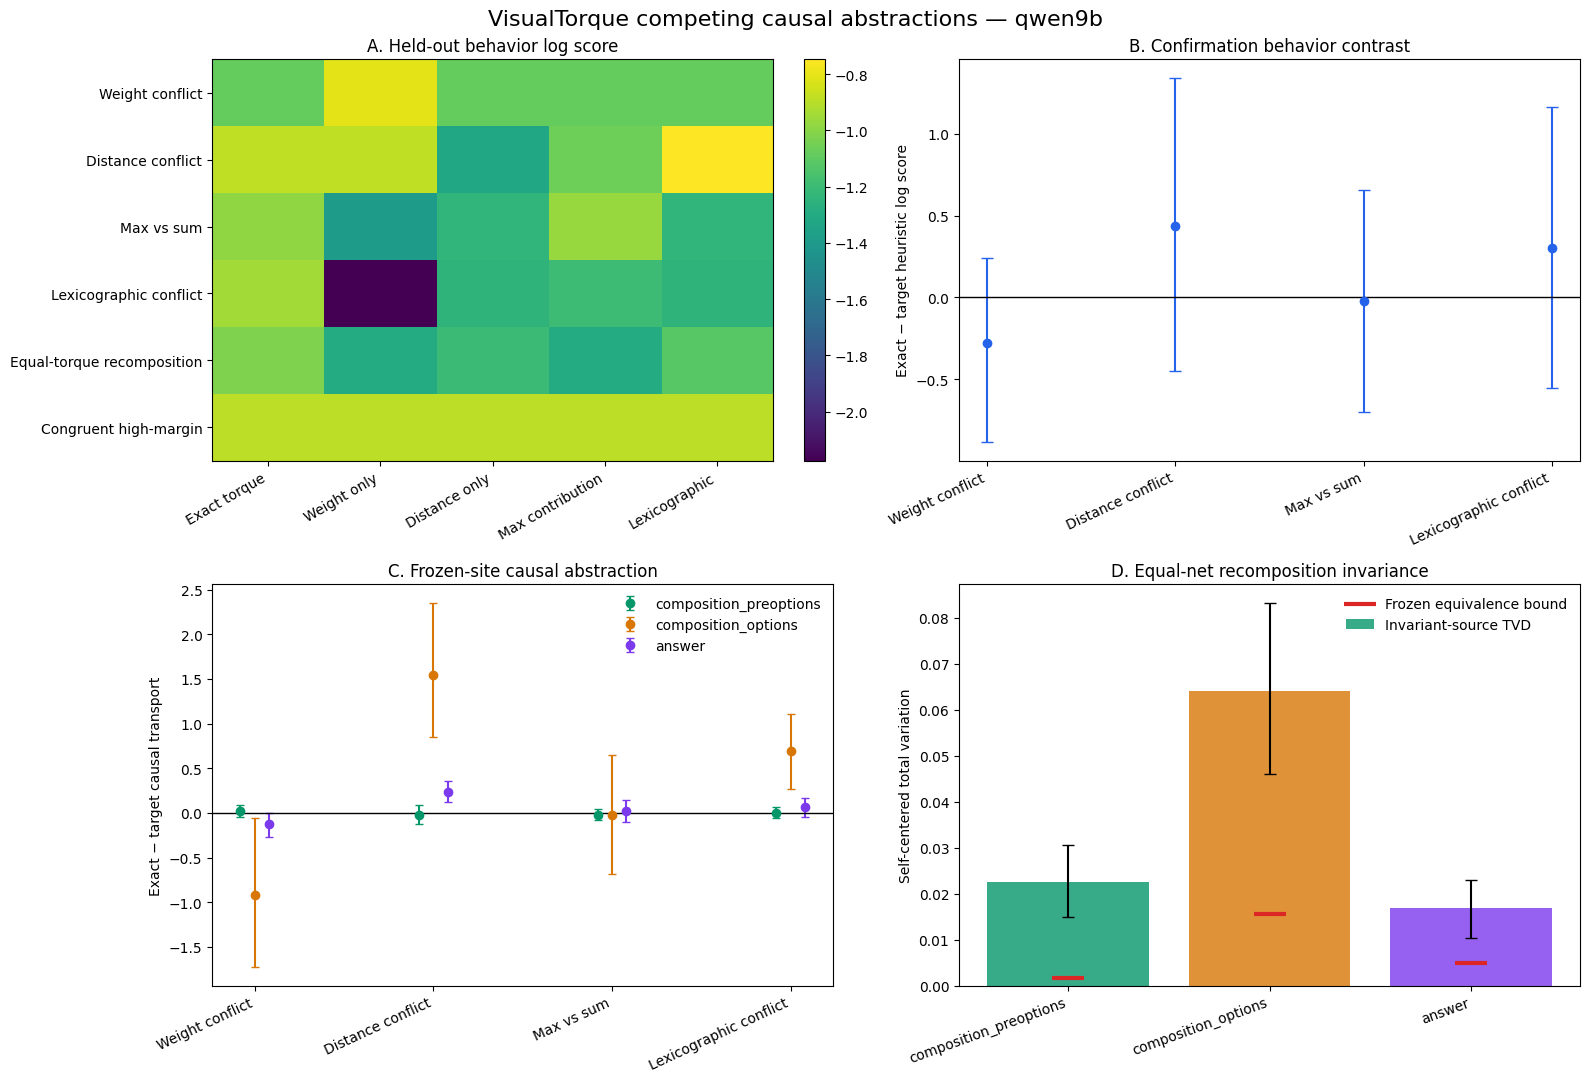

Saved: /content/drive/MyDrive/VisualTorque/results/competing_causal_abstraction_final_confirmatory_v1/models/Qwen__Qwen3.5-9B/analysis/figures/qwen9b_competing_causal_abstractions.png


In [16]:
%%cell_progress 15/17 Save the paper-facing competing-abstraction figure
cell_stage('Rendering held-out behavior, causal contrasts, and invariance')
import matplotlib.pyplot as plt

strategy_labels = {
    'exact_torque': 'Exact torque',
    'weight_only': 'Weight only',
    'distance_only': 'Distance only',
    'max_contribution': 'Max contribution',
    'lexicographic': 'Lexicographic',
}
cell_labels = {
    'weight_conflict': 'Weight conflict',
    'distance_conflict': 'Distance conflict',
    'max_vs_sum': 'Max vs sum',
    'lexicographic_conflict': 'Lexicographic conflict',
    'equal_torque_recomposition': 'Equal-torque recomposition',
    'congruent_high': 'Congruent high-margin',
}

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

heldout = confirmation_base.groupby([
    'diagnostic_cell', 'strategy'
])['log_probability'].mean().unstack()
heldout = heldout.reindex(
    index=DIAGNOSTIC_CELLS, columns=CANDIDATE_STRATEGIES
)
image = axes[0, 0].imshow(heldout.to_numpy(float), cmap='viridis', aspect='auto')
axes[0, 0].set_xticks(
    range(len(CANDIDATE_STRATEGIES)),
    [strategy_labels[value] for value in CANDIDATE_STRATEGIES],
    rotation=30, ha='right',
)
axes[0, 0].set_yticks(
    range(len(DIAGNOSTIC_CELLS)),
    [cell_labels[value] for value in DIAGNOSTIC_CELLS],
)
axes[0, 0].set_title('A. Held-out behavior log score')
fig.colorbar(image, ax=axes[0, 0], fraction=0.046)

behavior_plot = behavior_tests.set_index('diagnostic_cell').loc[
    list(TARGET_STRATEGY)
]
x = np.arange(len(behavior_plot))
axes[0, 1].errorbar(
    x, behavior_plot['estimate'],
    yerr=[
        np.maximum(0, behavior_plot['estimate'] - behavior_plot['ci_low']),
        np.maximum(0, behavior_plot['ci_high'] - behavior_plot['estimate']),
    ],
    fmt='o', capsize=4, color='#2563EB',
)
axes[0, 1].axhline(0, color='black', linewidth=1)
axes[0, 1].set_xticks(
    x, [cell_labels[value] for value in behavior_plot.index],
    rotation=25, ha='right',
)
axes[0, 1].set_ylabel('Exact − target heuristic log score')
axes[0, 1].set_title('B. Confirmation behavior contrast')

site_colors = {
    'composition_preoptions': '#059669',
    'composition_options': '#D97706',
    'answer': '#7C3AED',
}
for site_index, site_role in enumerate([site[2] for site in FROZEN_SITES]):
    rows = causal_tests[
        causal_tests['site_role'] == site_role
    ].set_index('diagnostic_cell').loc[list(TARGET_STRATEGY)]
    axes[1, 0].errorbar(
        x + (site_index - 1) * 0.08, rows['estimate'],
        yerr=[
            np.maximum(0, rows['estimate'] - rows['ci_low']),
            np.maximum(0, rows['ci_high'] - rows['estimate']),
        ],
        fmt='o', capsize=3, label=site_role,
        color=site_colors[site_role],
    )
axes[1, 0].axhline(0, color='black', linewidth=1)
axes[1, 0].set_xticks(
    x, [cell_labels[value] for value in TARGET_STRATEGY],
    rotation=25, ha='right',
)
axes[1, 0].set_ylabel('Exact − target causal transport')
axes[1, 0].set_title('C. Frozen-site causal abstraction')
axes[1, 0].legend(frameon=False)

invariance_plot = invariance_tests.set_index('site_role').loc[
    [site[2] for site in FROZEN_SITES]
]
x2 = np.arange(len(invariance_plot))
axes[1, 1].bar(
    x2, invariance_plot['estimate'], color=[
        site_colors[value] for value in invariance_plot.index
    ], alpha=0.8, label='Invariant-source TVD',
)
axes[1, 1].errorbar(
    x2, invariance_plot['estimate'],
    yerr=[
        np.maximum(0, invariance_plot['estimate'] - invariance_plot['ci_low']),
        np.maximum(0, invariance_plot['ci_high'] - invariance_plot['estimate']),
    ],
    fmt='none', capsize=4, color='black',
)
axes[1, 1].scatter(
    x2, invariance_plot['equivalence_bound'],
    marker='_', s=500, linewidths=3, color='#DC2626',
    label='Frozen equivalence bound',
)
axes[1, 1].set_xticks(x2, invariance_plot.index, rotation=20, ha='right')
axes[1, 1].set_ylabel('Self-centered total variation')
axes[1, 1].set_title('D. Equal-net recomposition invariance')
axes[1, 1].legend(frameon=False)

fig.suptitle(
    f'VisualTorque competing causal abstractions — {MODEL_KEY}',
    fontsize=16,
)
fig.tight_layout()
figure_path = FIGURE_DIR / f'{MODEL_KEY}_competing_causal_abstractions.png'
fig.savefig(figure_path, dpi=180, bbox_inches='tight')
plt.show()
print('Saved:', figure_path)


In [17]:
%%cell_progress 16/17 Apply the frozen abstraction decision tree
cell_stage('Combining held-out behavior and causal evidence without averaging them')

supported_rows = []
for cell_name, target_strategy in TARGET_STRATEGY.items():
    behavior = behavior_tests[
        behavior_tests['diagnostic_cell'] == cell_name
    ].iloc[0]
    causal = causal_tests[
        (causal_tests['diagnostic_cell'] == cell_name)
        & (causal_tests['site_role'] == PRIMARY_SITE_ROLE)
    ].iloc[0]
    behavior_exact = bool(
        behavior['ci_low'] > 0 and behavior['q_value'] < ALPHA
    )
    behavior_target = bool(
        behavior['ci_high'] < 0 and behavior['q_value'] < ALPHA
    )
    causal_exact = bool(
        causal['ci_low'] > 0 and causal['q_value'] < ALPHA
    )
    causal_target = bool(
        causal['ci_high'] < 0 and causal['q_value'] < ALPHA
    )
    if behavior_exact and causal_exact:
        label = 'exact_torque'
    elif behavior_target and causal_target:
        label = target_strategy
    elif (
        (behavior_exact and causal_target)
        or (behavior_target and causal_exact)
    ):
        label = 'behavior_causal_dissociation'
    else:
        label = 'unresolved'
    supported_rows.append({
        'diagnostic_cell': cell_name,
        'competing_strategy': target_strategy,
        'supported_abstraction': label,
        'behavior_estimate': float(behavior['estimate']),
        'behavior_ci_low': float(behavior['ci_low']),
        'behavior_ci_high': float(behavior['ci_high']),
        'behavior_q': float(behavior['q_value']),
        'causal_estimate': float(causal['estimate']),
        'causal_ci_low': float(causal['ci_low']),
        'causal_ci_high': float(causal['ci_high']),
        'causal_q': float(causal['q_value']),
    })

supported_frame = pd.DataFrame(supported_rows)
resolved = supported_frame[
    ~supported_frame['supported_abstraction'].isin([
        'unresolved', 'behavior_causal_dissociation'
    ])
]
dissociations = int((
    supported_frame['supported_abstraction']
    == 'behavior_causal_dissociation'
).sum())
conditional_selector_supported = bool(selector_test['ci_low'] > 0)
primary_invariance = invariance_tests[
    invariance_tests['site_role'] == PRIMARY_SITE_ROLE
].iloc[0]
exact_value_invariance_supported = bool(primary_invariance['equivalent'])
primary_invariance_payload = {
    'site_role': str(primary_invariance['site_role']),
    'n': int(primary_invariance['n']),
    'estimate': float(primary_invariance['estimate']),
    'ci_low': float(primary_invariance['ci_low']),
    'ci_high': float(primary_invariance['ci_high']),
    'equivalence_bound': float(primary_invariance['equivalence_bound']),
    'equivalent': bool(primary_invariance['equivalent']),
}

if (
    conditional_selector_supported
    and len(resolved) >= 2
    and resolved['supported_abstraction'].nunique() >= 2
):
    decision = 'conditional_model_specific_abstraction_supported'
elif len(resolved) == len(TARGET_STRATEGY) and bool(
    (resolved['supported_abstraction'] == 'exact_torque').all()
):
    decision = 'single_exact_torque_abstraction_supported'
elif dissociations >= 2:
    decision = 'behavior_causal_strategy_dissociation_supported'
elif len(resolved) >= 2:
    decision = 'partial_condition_specific_abstraction_supported'
else:
    decision = 'candidate_abstractions_unresolved_or_incomplete'

decision_payload = {
    'schema_version': 'competing-causal-abstraction-decision-1.0',
    'decision': decision,
    'model_key': MODEL_KEY,
    'model_id': MODEL_ID,
    'model_revision': MODEL_REVISION,
    'manifest_sha256': manifest_sha256,
    'protocol_sha256': protocol_sha256,
    'calibration_mapping': calibration_mapping,
    'calibration_prediction_equivalence_classes': (
        calibration_equivalence_classes
    ),
    'global_calibration_strategy': global_strategy,
    'conditional_selector_test': selector_test,
    'conditional_selector_supported': conditional_selector_supported,
    'supported_abstractions': supported_rows,
    'exact_value_invariance_supported': exact_value_invariance_supported,
    'primary_invariance_test': primary_invariance_payload,
    'nonce_semantics_audit': nonce_audit,
    'limitations': [
        'The candidate set is deliberately finite; unresolved results may indicate a missing strategy.',
        'Grouped residual-stream patching tests sufficient transport at frozen sites, not a unique circuit.',
        'Equal-net invariance is an equivalence claim only at the preregistered effect scale.',
        'The scenes are newly generated but retain the schematic VisualTorque renderer.',
        'A conditional selector predicts model behavior; it is not a claim that the model explicitly represents a discrete strategy variable.',
        'No claim is made that human physical judgment follows a complete serial torque calculation.',
    ],
}
DECISION_PATH = ANALYSIS_DIR / 'abstraction_decision.json'
write_json_atomic(DECISION_PATH, decision_payload)
supported_frame.to_csv(
    ANALYSIS_DIR / 'supported_abstractions.csv', index=False
)
print(json.dumps(decision_payload, indent=2))


Apply the frozen abstraction decision tree:  88%|########8 | 15/17 [00:00<?, ?cell/s]

{
  "schema_version": "competing-causal-abstraction-decision-1.0",
  "decision": "candidate_abstractions_unresolved_or_incomplete",
  "model_key": "qwen9b",
  "model_id": "Qwen/Qwen3.5-9B",
  "model_revision": "c202236235762e1c871ad0ccb60c8ee5ba337b9a",
  "manifest_sha256": "sha256:bd1610f6aa99c4ff196e79a55a2ff10eeaa824289c462eec6b9cefe4d803e9a8",
  "protocol_sha256": "sha256:e084ec19d013eea52df8eca6cd8d649408be06048cb54bddbc5566f5c3f05ef9",
  "calibration_mapping": {
    "weight_conflict": "weight_only",
    "distance_conflict": "exact_torque",
    "max_vs_sum": "max_contribution",
    "lexicographic_conflict": "max_contribution",
    "equal_torque_recomposition": "max_contribution",
    "congruent_high": "max_contribution"
  },
  "calibration_prediction_equivalence_classes": {
    "weight_conflict": [
      "weight_only"
    ],
    "distance_conflict": [
      "exact_torque",
      "weight_only"
    ],
    "max_vs_sum": [
      "max_contribution"
    ],
    "lexicographic_conflict": 

In [18]:
%%cell_progress 17/17 Export claim cards and optional cross-model synthesis
cell_stage('Writing the model report and checking the three-model panel')

interpretations = {
    'conditional_model_specific_abstraction_supported': (
        'The best held-out strategy changes across diagnostic conditions, '
        'and frozen-site causal transport supports at least two distinct '
        'condition-specific abstractions.'
    ),
    'single_exact_torque_abstraction_supported': (
        'Exact torque beats every preregistered heuristic in both held-out '
        'behavior and primary-site causal transport.'
    ),
    'behavior_causal_strategy_dissociation_supported': (
        'The strategy that best describes clean behavior does not reliably '
        'match the abstraction transported by the frozen internal site.'
    ),
    'partial_condition_specific_abstraction_supported': (
        'Some conditions support a specific abstraction, but the complete '
        'conditional-selector claim does not pass its held-out gate.'
    ),
    'candidate_abstractions_unresolved_or_incomplete': (
        'The frozen candidate set does not yield enough convergent behavior '
        'and causal evidence for a strategy label.'
    ),
}

report_lines = [
    f'# Competing causal abstractions — {MODEL_KEY}', '',
    f"- Decision: {decision_payload['decision']}",
    f'- Model: {MODEL_ID}',
    f'- Revision: {MODEL_REVISION}',
    f'- Calibration families: {len(calibration.family_id.unique())}',
    f'- Confirmation families: {len(confirmation_base.family_id.unique())}',
    f'- Conditional selector supported: {conditional_selector_supported}',
    f'- Equal-net invariance supported: {exact_value_invariance_supported}', '',
    '## Interpretation', '', interpretations[decision], '',
    '## Condition-level abstractions', '',
]
for row in supported_rows:
    report_lines.append(
        f"- {row['diagnostic_cell']}: {row['supported_abstraction']} "
        f"(behavior={row['behavior_estimate']:.3f}, "
        f"causal={row['causal_estimate']:.3f})"
    )
report_lines.extend([
    '', '## Evidence boundary', '',
    'A condition receives a strategy label only when held-out clean behavior '
    'and self-replay-centered mirror intervention favor the same candidate. '
    'Correctness never filters the support. Equal-net recomposition, nonce '
    'semantics, orientation, leave-one-out stability, and replay parity are '
    'reported separately.', '',
    '## Next experiment', '',
    'After all three model runs, perform the frozen terminal fallback/path '
    'audit. Do not add another candidate strategy in response to confirmation '
    'results without versioning a new discovery experiment.', '',
])
REPORT_PATH = ANALYSIS_DIR / 'abstraction_report.md'
REPORT_PATH.write_text('\n'.join(report_lines) + '\n', encoding='utf-8')
write_json_atomic(ANALYSIS_DIR / 'paper_claim_card.json', {
    'decision': decision,
    'interpretation': interpretations[decision],
    'supported_abstractions': supported_rows,
    'conditional_selector_supported': conditional_selector_supported,
    'exact_value_invariance_supported': exact_value_invariance_supported,
    'nonclaim': (
        'This experiment does not identify a unique circuit, prove serial '
        'multiplication, or claim that humans always explicitly calculate torque.'
    ),
})

model_outputs = {
    key: SHARED_ROOT / 'models' / spec['model_slug'] / 'analysis'
    for key, spec in MODEL_SPECS.items()
}
missing = [
    key for key, path in model_outputs.items()
    if not (path / 'abstraction_decision.json').is_file()
]
if missing:
    print(REPORT_PATH.read_text(encoding='utf-8'))
    print('\nCross-model synthesis pending. Run fresh runtimes for:', missing)
else:
    cell_stage('Running exact-manifest cross-model paired synthesis')
    decision_rows = []
    behavior_effect_frames = []
    causal_effect_frames = []
    for key, path in model_outputs.items():
        payload = json.loads(
            (path / 'abstraction_decision.json').read_text(encoding='utf-8')
        )
        decision_rows.extend({
            'model_key': key,
            'diagnostic_cell': row['diagnostic_cell'],
            'supported_abstraction': row['supported_abstraction'],
            'behavior_estimate': row['behavior_estimate'],
            'causal_estimate': row['causal_estimate'],
            'decision': payload['decision'],
        } for row in payload['supported_abstractions'])
        behavior_effect_frames.append(pd.read_csv(
            path / 'family_behavior_effects.csv'
        ))
        causal = pd.read_csv(path / 'family_causal_effects.csv')
        causal_effect_frames.append(causal[
            causal['site_role'] == PRIMARY_SITE_ROLE
        ])
    cross_decisions = pd.DataFrame(decision_rows)
    cross_behavior = pd.concat(behavior_effect_frames, ignore_index=True)
    cross_causal = pd.concat(causal_effect_frames, ignore_index=True)
    cross_tests = []
    model_pairs = (
        ('qwen9b', 'gemma12b'),
        ('qwen9b', 'qwen27b'),
        ('gemma12b', 'qwen27b'),
    )
    for metric_name, frame, value_column in (
        ('behavior', cross_behavior, 'exact_minus_target_behavior'),
        ('causal', cross_causal, 'exact_minus_target_causal'),
    ):
        for cell_name in TARGET_STRATEGY:
            pivot = frame[
                frame['diagnostic_cell'] == cell_name
            ].pivot(index='family_id', columns='model_key', values=value_column)
            for left, right in model_pairs:
                values = (pivot[left] - pivot[right]).dropna()
                test = bootstrap_mean(
                    values,
                    seed=SEED + 500 + len(cross_tests),
                )
                cross_tests.append({
                    'metric': metric_name,
                    'diagnostic_cell': cell_name,
                    'left_model': left,
                    'right_model': right,
                    **test,
                })
    cross_tests = pd.DataFrame(cross_tests)
    cross_tests['q_value'] = bh_adjust(cross_tests['p_value'])
    cross_decisions.to_csv(
        CROSS_MODEL_DIR / 'cross_model_supported_abstractions.csv', index=False
    )
    cross_tests.to_csv(
        CROSS_MODEL_DIR / 'paired_cross_model_tests.csv', index=False
    )
    cross_report = [
        '# Cross-model competing causal abstractions', '',
        'All models use the exact same newly generated family manifest and '
        'model-specific previously frozen depth map.', '',
    ]
    for _, row in cross_decisions.iterrows():
        cross_report.append(
            f"- {row['model_key']} / {row['diagnostic_cell']}: "
            f"{row['supported_abstraction']}"
        )
    (CROSS_MODEL_DIR / 'cross_model_report.md').write_text(
        '\n'.join(cross_report) + '\n', encoding='utf-8'
    )
    print(REPORT_PATH.read_text(encoding='utf-8'))
    print('\nCross-model synthesis:', CROSS_MODEL_DIR)


Export claim cards and optional cross-model synthesis:  94%|#########4| 16/17 [00:00<?, ?cell/s]

# Competing causal abstractions — qwen9b

- Decision: candidate_abstractions_unresolved_or_incomplete
- Model: Qwen/Qwen3.5-9B
- Revision: c202236235762e1c871ad0ccb60c8ee5ba337b9a
- Calibration families: 48
- Confirmation families: 72
- Conditional selector supported: False
- Equal-net invariance supported: False

## Interpretation

The frozen candidate set does not yield enough convergent behavior and causal evidence for a strategy label.

## Condition-level abstractions

- weight_conflict: unresolved (behavior=-0.281, causal=0.021)
- distance_conflict: unresolved (behavior=0.437, causal=-0.021)
- max_vs_sum: unresolved (behavior=-0.021, causal=-0.021)
- lexicographic_conflict: unresolved (behavior=0.302, causal=0.000)

## Evidence boundary

A condition receives a strategy label only when held-out clean behavior and self-replay-centered mirror intervention favor the same candidate. Correctness never filters the support. Equal-net recomposition, nonce semantics, orientation, leave-one-